In [1]:
# ============================================================
# CELL 1 — Setup, configuration, environment audit
# TurnAhead: Departure-Disruption Early Warning
# ============================================================
import os
import sys
import gc
import glob
import json
import time
import math
import random
import warnings
import platform
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
import pyarrow as pa
import pyarrow.parquet as pq

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score, recall_score,
    f1_score, brier_score_loss, confusion_matrix, precision_recall_curve,
    roc_curve,
)
import lightgbm as lgb

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Optional libraries (imported safely; notebook adapts if missing)
try:
    import polars as pl
except ImportError:
    pl = None

# ------------------------------------------------------------
# Configuration constants
# ------------------------------------------------------------
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)

INPUT_ROOT = Path("/kaggle/input")
KAGGLEHUB_CACHE = Path.home() / ".cache" / "kagglehub"
PROCESSED_DIR = Path("/kaggle/working/processed")
REPORTS_DIR = Path("/kaggle/working/reports")

# Resolved in the discovery step below (do not hardcode)
INPUT_CSV_PATH = None
CSV_FILENAME_HINT = "airline.csv.shuffle"

# Modeling window
MODEL_START = pd.Timestamp("2006-01-01")
MODEL_END = pd.Timestamp("2008-04-30")
MIN_YEAR = 2006  # chunk-level prefilter: Year >= 2006

# Chronological splits (inclusive)
TRAIN_START, TRAIN_END = pd.Timestamp("2006-01-01"), pd.Timestamp("2007-06-30")
VAL_START, VAL_END = pd.Timestamp("2007-07-01"), pd.Timestamp("2007-12-31")
TEST_START, TEST_END = pd.Timestamp("2008-01-01"), pd.Timestamp("2008-04-30")

# Robustness-check splits
ROBUST_TRAIN_START, ROBUST_TRAIN_END = pd.Timestamp("2006-01-01"), pd.Timestamp("2006-12-31")
ROBUST_TEST_START, ROBUST_TEST_END = pd.Timestamp("2007-01-01"), pd.Timestamp("2007-12-31")

# Target definition
DELAY_THRESHOLD_MIN = 15  # is_delayed_15 = 1 if DepDelay >= 15
TOP_N_ORIGINS = 40

# Columns to read (usecols). Leaky columns are deliberately NOT read except
# those needed for rotation reconstruction (ArrTime/ArrDelay of the PRIOR leg),
# the audit frames (Cancelled/Diverted/CancellationCode), and EDA-only delay causes.
USECOLS = [
    "Year", "Month", "DayofMonth", "DayOfWeek",
    "DepTime", "CRSDepTime", "ArrTime", "CRSArrTime",
    "UniqueCarrier", "FlightNum", "TailNum",
    "CRSElapsedTime", "ArrDelay", "DepDelay",
    "Origin", "Dest", "Distance",
    "Cancelled", "CancellationCode", "Diverted",
    "CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay",
]

# Fields that must NEVER be model features (enforced again later in code)
LEAKY_FIELDS = [
    "DepTime", "ArrTime", "ArrDelay", "ActualElapsedTime", "AirTime",
    "TaxiIn", "TaxiOut", "CarrierDelay", "WeatherDelay", "NASDelay",
    "SecurityDelay", "LateAircraftDelay",
]
EDA_ONLY_FIELDS = ["CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay"]

# Directories
for d in (PROCESSED_DIR, REPORTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Plot defaults
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def human_size(n_bytes):
    n = float(n_bytes)
    for unit in ["B", "KB", "MB", "GB", "TB"]:
        if n < 1024 or unit == "TB":
            return f"{n:,.2f} {unit}"
        n /= 1024

def list_files_with_sizes(root, max_files=200):
    rows = []
    if not Path(root).exists():
        return rows
    for p in Path(root).rglob("*"):
        if p.is_file():
            try:
                rows.append((str(p), p.stat().st_size))
            except OSError:
                pass
        if len(rows) >= max_files:
            break
    return sorted(rows)

def safe_version(mod):
    return getattr(mod, "__version__", "unknown")

# ------------------------------------------------------------
# 1) Kaggle input files + sizes
# ------------------------------------------------------------
print("=" * 78)
print("KAGGLE INPUT FILES")
print("=" * 78)
input_files = list_files_with_sizes(INPUT_ROOT)
if not input_files:
    print(f"No files found under {INPUT_ROOT}. Attach the dataset via 'Add Input'.")
for fp, sz in input_files:
    print(f"{human_size(sz):>12}  {fp}")

# ------------------------------------------------------------
# 2) Locate the airline CSV (no hardcoded dataset slug)
# ------------------------------------------------------------
candidates = [fp for fp, _ in input_files if CSV_FILENAME_HINT in Path(fp).name.lower()]
if not candidates:
    candidates = [fp for fp, _ in input_files
                  if Path(fp).name.lower().endswith((".csv", ".shuffle", ".csv.shuffle"))]

# Fallback: kagglehub cache, only if already downloaded in this session
if not candidates and KAGGLEHUB_CACHE.exists():
    cache_files = list_files_with_sizes(KAGGLEHUB_CACHE, max_files=500)
    candidates = [fp for fp, _ in cache_files if CSV_FILENAME_HINT in Path(fp).name.lower()]
    if candidates:
        print("\nNote: using a kagglehub cache copy (this consumes working-disk space).")

print("\n" + "=" * 78)
print("INPUT FILE RESOLUTION")
print("=" * 78)
if candidates:
    # Prefer the largest candidate if several match
    candidates = sorted(candidates, key=lambda p: os.path.getsize(p), reverse=True)
    INPUT_CSV_PATH = candidates[0]
    print(f"Resolved INPUT_CSV_PATH = {INPUT_CSV_PATH}")
    print(f"Size                    = {human_size(os.path.getsize(INPUT_CSV_PATH))}")
    if len(candidates) > 1:
        print("Other candidates:", candidates[1:])
else:
    print("!! airline.csv.shuffle NOT FOUND.")
    print("   Fix: right sidebar -> Add Input -> search 'data-expo-2009-airline-on-time-data'.")
    print("   Then re-run this cell. Do NOT proceed to CELL 2 until a path is resolved.")

# ------------------------------------------------------------
# 3) Configuration summary
# ------------------------------------------------------------
config_summary = {
    "random_seed": RANDOM_SEED,
    "input_csv_path": INPUT_CSV_PATH,
    "processed_dir": str(PROCESSED_DIR),
    "reports_dir": str(REPORTS_DIR),
    "model_window": [str(MODEL_START.date()), str(MODEL_END.date())],
    "train": [str(TRAIN_START.date()), str(TRAIN_END.date())],
    "validation": [str(VAL_START.date()), str(VAL_END.date())],
    "test": [str(TEST_START.date()), str(TEST_END.date())],
    "robustness_train": [str(ROBUST_TRAIN_START.date()), str(ROBUST_TRAIN_END.date())],
    "robustness_test": [str(ROBUST_TEST_START.date()), str(ROBUST_TEST_END.date())],
    "delay_threshold_min": DELAY_THRESHOLD_MIN,
    "top_n_origins": TOP_N_ORIGINS,
    "usecols": USECOLS,
    "leaky_fields": LEAKY_FIELDS,
}
print("\n" + "=" * 78)
print("CONFIGURATION")
print("=" * 78)
print(json.dumps(config_summary, indent=2, default=str))

with open(REPORTS_DIR / "config_summary.json", "w") as f:
    json.dump(config_summary, f, indent=2, default=str)

# ------------------------------------------------------------
# 4) Library versions (safe)
# ------------------------------------------------------------
print("\n" + "=" * 78)
print("ENVIRONMENT / LIBRARY VERSIONS")
print("=" * 78)
versions = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": safe_version(np),
    "pandas": safe_version(pd),
    "matplotlib": safe_version(matplotlib),
    "seaborn": safe_version(sns),
    "scipy": safe_version(scipy),
    "scikit-learn": safe_version(sklearn),
    "lightgbm": safe_version(lgb),
    "pyarrow": safe_version(pa),
    "polars": safe_version(pl) if pl is not None else "not installed (optional)",
}
for k, v in versions.items():
    print(f"{k:>14}: {v}")

# ------------------------------------------------------------
# 5) Directories and resource check
# ------------------------------------------------------------
print("\n" + "=" * 78)
print("OUTPUT DIRECTORIES")
print("=" * 78)
for d in (PROCESSED_DIR, REPORTS_DIR):
    print(f"{str(d):<36} exists={d.exists()}  writable={os.access(d, os.W_OK)}")

try:
    import shutil
    total, used, free = shutil.disk_usage("/kaggle/working")
    print(f"\n/kaggle/working disk: total={human_size(total)}, used={human_size(used)}, free={human_size(free)}")
except Exception as e:
    print("Disk check skipped:", e)

try:
    import psutil
    vm = psutil.virtual_memory()
    print(f"RAM: total={human_size(vm.total)}, available={human_size(vm.available)}")
except Exception:
    print("RAM check skipped (psutil unavailable).")

print(f"\nCELL 1 complete at {datetime.now():%Y-%m-%d %H:%M:%S}. "
      f"Ready for CELL 2: {INPUT_CSV_PATH is not None}")

KAGGLE INPUT FILES
No files found under /kaggle/input. Attach the dataset via 'Add Input'.

INPUT FILE RESOLUTION
!! airline.csv.shuffle NOT FOUND.
   Fix: right sidebar -> Add Input -> search 'data-expo-2009-airline-on-time-data'.
   Then re-run this cell. Do NOT proceed to CELL 2 until a path is resolved.

CONFIGURATION
{
  "random_seed": 42,
  "input_csv_path": null,
  "processed_dir": "/kaggle/working/processed",
  "reports_dir": "/kaggle/working/reports",
  "model_window": [
    "2006-01-01",
    "2008-04-30"
  ],
  "train": [
    "2006-01-01",
    "2007-06-30"
  ],
  "validation": [
    "2007-07-01",
    "2007-12-31"
  ],
  "test": [
    "2008-01-01",
    "2008-04-30"
  ],
  "robustness_train": [
    "2006-01-01",
    "2006-12-31"
  ],
  "robustness_test": [
    "2007-01-01",
    "2007-12-31"
  ],
  "delay_threshold_min": 15,
  "top_n_origins": 40,
  "usecols": [
    "Year",
    "Month",
    "DayofMonth",
    "DayOfWeek",
    "DepTime",
    "CRSDepTime",
    "ArrTime",
    "CRSAr

In [2]:
DOWNLOAD_VIA_KAGGLEHUB = True
MIN_DATA_FILE_BYTES = 200 * 1024**2
DATA_SUFFIXES = (".csv", ".shuffle", ".gz", ".bz2", ".zip", ".txt", ".tsv")

search_roots = [INPUT_ROOT]
if INPUT_CSV_PATH is None and DOWNLOAD_VIA_KAGGLEHUB:
    import kagglehub
    dl_path = kagglehub.dataset_download("wenxingdi/data-expo-2009-airline-on-time-data")
    print("kagglehub path:", dl_path)
    search_roots.append(Path(dl_path))
if KAGGLEHUB_CACHE.exists():
    search_roots.append(KAGGLEHUB_CACHE)

all_files = []
for root in search_roots:
    if Path(root).exists():
        for p in Path(root).rglob("*"):
            if p.is_file():
                all_files.append((str(p), p.stat().st_size))
all_files = sorted(set(all_files), key=lambda t: t[1], reverse=True)

print("\nFiles found (largest first, top 40):")
for fp, sz in all_files[:40]:
    print(f"{human_size(sz):>12}  {fp}")

if INPUT_CSV_PATH is None:
    named = [fp for fp, _ in all_files if CSV_FILENAME_HINT in Path(fp).name.lower()]
    sized = [fp for fp, sz in all_files
             if sz >= MIN_DATA_FILE_BYTES and Path(fp).name.lower().endswith(DATA_SUFFIXES)]
    pool = named or sized
    if not pool:
        raise FileNotFoundError(
            "No data-like file >= 200 MB found. Paste the 'Files found' list above."
        )
    INPUT_CSV_PATH = pool[0]

print("\nINPUT_CSV_PATH:", INPUT_CSV_PATH)
print("Size:", human_size(os.path.getsize(INPUT_CSV_PATH)))

with open(INPUT_CSV_PATH, "rb") as fh:
    magic = fh.read(4)
if magic[:2] == b"\x1f\x8b":
    CSV_COMPRESSION = "gzip"
elif magic[:2] == b"PK":
    CSV_COMPRESSION = "zip"
elif magic[:3] == b"BZh":
    CSV_COMPRESSION = "bz2"
else:
    CSV_COMPRESSION = None
print("Detected compression:", CSV_COMPRESSION)

header_cols = pd.read_csv(INPUT_CSV_PATH, nrows=0, compression=CSV_COMPRESSION).columns.tolist()
print(f"\nHeader columns ({len(header_cols)}):")
print(header_cols)

lower_map = {c.strip().lower(): c for c in header_cols}
REQUIRED_COLS = [
    "Year", "Month", "DayofMonth", "DayOfWeek", "CRSDepTime", "CRSArrTime", "ArrTime",
    "UniqueCarrier", "FlightNum", "TailNum", "CRSElapsedTime", "ArrDelay", "DepDelay",
    "Origin", "Dest", "Distance", "Cancelled", "Diverted", "DepTime",
]
OPTIONAL_COLS = ["CancellationCode", "CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay"]

missing_required = [c for c in REQUIRED_COLS if c.lower() not in lower_map]
missing_optional = [c for c in OPTIONAL_COLS if c.lower() not in lower_map]
if missing_required:
    raise KeyError(f"Missing required columns: {missing_required}. Paste the header above so I can adapt.")
if missing_optional:
    print("\nWARNING: optional columns missing (EDA/audit only):", missing_optional)

USECOLS_RESOLVED = [lower_map[c.lower()] for c in USECOLS if c.lower() in lower_map]
RENAME_MAP = {lower_map[c.lower()]: c for c in USECOLS if c.lower() in lower_map and lower_map[c.lower()] != c}
print("\nUSECOLS_RESOLVED count:", len(USECOLS_RESOLVED))
print("RENAME_MAP (actual -> canonical):", RENAME_MAP if RENAME_MAP else "none needed")

sample = pd.read_csv(
    INPUT_CSV_PATH, nrows=50000, usecols=USECOLS_RESOLVED, compression=CSV_COMPRESSION
).rename(columns=RENAME_MAP)

print("\nSample shape:", sample.shape)
print("\nDtypes:")
print(sample.dtypes.to_string())

print("\nFirst 5 rows:")
print(sample.head().to_string())

print("\nYear distribution in sample (shuffle check):")
print(sample["Year"].value_counts().sort_index().to_string())

print("\nNull rate by column:")
print((sample.isna().mean() * 100).round(2).sort_values(ascending=False).to_string())

print("\nCRSDepTime range:", sample["CRSDepTime"].min(), "to", sample["CRSDepTime"].max())
print("Distinct TailNum values (top 5):", sample["TailNum"].value_counts().head(5).to_dict())
print("Cancelled values:", sorted(sample["Cancelled"].dropna().unique().tolist()))
print("Diverted values:", sorted(sample["Diverted"].dropna().unique().tolist()))

schema_report = {
    "input_csv_path": INPUT_CSV_PATH,
    "compression": CSV_COMPRESSION,
    "header_columns": header_cols,
    "usecols_resolved": USECOLS_RESOLVED,
    "rename_map": RENAME_MAP,
    "missing_optional": missing_optional,
}
with open(REPORTS_DIR / "schema_check.json", "w") as f:
    json.dump(schema_report, f, indent=2)

del sample
gc.collect()


Mounting files to /kaggle/input/datasets/wenxingdi/data-expo-2009-airline-on-time-data...
kagglehub path: /kaggle/input/datasets/wenxingdi/data-expo-2009-airline-on-time-data

Files found (largest first, top 40):
   670.32 MB  /kaggle/input/datasets/wenxingdi/data-expo-2009-airline-on-time-data/2007.csv
   640.93 MB  /kaggle/input/datasets/wenxingdi/data-expo-2009-airline-on-time-data/2006.csv
   639.94 MB  /kaggle/input/datasets/wenxingdi/data-expo-2009-airline-on-time-data/2005.csv
   638.85 MB  /kaggle/input/datasets/wenxingdi/data-expo-2009-airline-on-time-data/2004.csv
   597.71 MB  /kaggle/input/datasets/wenxingdi/data-expo-2009-airline-on-time-data/2003.csv
   572.60 MB  /kaggle/input/datasets/wenxingdi/data-expo-2009-airline-on-time-data/2001.csv
   543.74 MB  /kaggle/input/datasets/wenxingdi/data-expo-2009-airline-on-time-data/2000.csv
   527.31 MB  /kaggle/input/datasets/wenxingdi/data-expo-2009-airline-on-time-data/1999.csv
   515.32 MB  /kaggle/input/datasets/wenxingdi/data

33

In [3]:
DATA_DIR = None
try:
    DATA_DIR = Path(INPUT_CSV_PATH).parent
except Exception:
    pass
if DATA_DIR is None or not (DATA_DIR / "2006.csv").exists():
    found = sorted(INPUT_ROOT.rglob("2006.csv"))
    if not found:
        raise FileNotFoundError("2006.csv not found under /kaggle/input")
    DATA_DIR = found[0].parent

YEARS = list(range(MIN_YEAR, MODEL_END.year + 1))
INPUT_FILES = {y: DATA_DIR / f"{y}.csv" for y in YEARS}
for y, p in INPUT_FILES.items():
    print(y, p, human_size(p.stat().st_size) if p.exists() else "MISSING")
missing_files = [str(p) for p in INPUT_FILES.values() if not p.exists()]
if missing_files:
    raise FileNotFoundError(missing_files)

RAW_DIR = PROCESSED_DIR / "raw_subset"
RAW_DIR.mkdir(parents=True, exist_ok=True)
for old in RAW_DIR.glob("*.parquet"):
    old.unlink()

CHUNKSIZE = 1_000_000
STR_COLS = ["UniqueCarrier", "TailNum", "Origin", "Dest", "CancellationCode"]
INT_KEY_COLS = ["Year", "Month", "DayofMonth", "DayOfWeek", "CRSDepTime", "CRSArrTime", "Cancelled", "Diverted"]
FLOAT_COLS = ["DepTime", "ArrTime", "CRSElapsedTime", "ArrDelay", "DepDelay", "Distance",
              "CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay"]

DTYPE_CANON = {c: "float32" for c in FLOAT_COLS + INT_KEY_COLS + ["FlightNum"]}
DTYPE_CANON.update({c: str for c in STR_COLS})

SCHEMA = pa.schema([
    ("row_id", pa.int64()), ("flight_date", pa.timestamp("ns")),
    ("Year", pa.int16()), ("Month", pa.int8()), ("DayofMonth", pa.int8()), ("DayOfWeek", pa.int8()),
    ("DepTime", pa.float32()), ("CRSDepTime", pa.int16()),
    ("ArrTime", pa.float32()), ("CRSArrTime", pa.int16()),
    ("UniqueCarrier", pa.string()), ("FlightNum", pa.int32()), ("TailNum", pa.string()),
    ("CRSElapsedTime", pa.float32()), ("ArrDelay", pa.float32()), ("DepDelay", pa.float32()),
    ("Origin", pa.string()), ("Dest", pa.string()), ("Distance", pa.float32()),
    ("Cancelled", pa.int8()), ("CancellationCode", pa.string()), ("Diverted", pa.int8()),
    ("CarrierDelay", pa.float32()), ("WeatherDelay", pa.float32()), ("NASDelay", pa.float32()),
    ("SecurityDelay", pa.float32()), ("LateAircraftDelay", pa.float32()),
])

INT_CAST = {"Year": "int16", "Month": "int8", "DayofMonth": "int8", "DayOfWeek": "int8",
            "CRSDepTime": "int16", "CRSArrTime": "int16", "Cancelled": "int8", "Diverted": "int8"}

def process_chunk(df, rename_map, offset):
    stats = {"rows_in": len(df)}
    df = df.rename(columns=rename_map)
    df["row_id"] = np.arange(offset, offset + len(df), dtype=np.int64)

    ok_keys = df[INT_KEY_COLS].notna().all(axis=1)
    stats["bad_keys"] = int((~ok_keys).sum())
    df = df.loc[ok_keys].copy()

    for c, t in INT_CAST.items():
        df[c] = df[c].astype(t)

    dates = pd.to_datetime(
        pd.DataFrame({"year": df["Year"].astype("int32"),
                      "month": df["Month"].astype("int32"),
                      "day": df["DayofMonth"].astype("int32")}),
        errors="coerce",
    )
    stats["bad_dates"] = int(dates.isna().sum())
    in_window = dates.notna() & (dates >= MODEL_START) & (dates <= MODEL_END)
    stats["out_of_window"] = int((dates.notna() & ~in_window).sum())

    df = df.loc[in_window].copy()
    df["flight_date"] = dates.loc[in_window].values

    for c in STR_COLS:
        df[c] = df[c].str.strip()
    df["FlightNum"] = pd.to_numeric(df["FlightNum"], errors="coerce").astype("Int32")
    for c in FLOAT_COLS:
        df[c] = df[c].astype("float32")

    stats["rows_kept"] = len(df)
    return df[SCHEMA.names], stats

ingest_rows = []
t_start = time.time()

for y, path in INPUT_FILES.items():
    header = pd.read_csv(path, nrows=0).columns.tolist()
    lm = {c.strip().lower(): c for c in header}
    miss = [c for c in USECOLS if c.lower() not in lm]
    if miss:
        raise KeyError(f"{path.name} missing columns: {miss}")
    usecols_y = [lm[c.lower()] for c in USECOLS]
    rename_map = {lm[c.lower()]: c for c in USECOLS if lm[c.lower()] != c}
    dtype_y = {lm[c.lower()]: t for c, t in DTYPE_CANON.items()}

    out_path = RAW_DIR / f"flights_{y}.parquet"
    writer = pq.ParquetWriter(out_path, SCHEMA, compression="zstd")
    tot = {"rows_in": 0, "bad_keys": 0, "bad_dates": 0, "out_of_window": 0, "rows_kept": 0}
    offset = y * 10_000_000
    t_file = time.time()

    try:
        reader = pd.read_csv(path, usecols=usecols_y, dtype=dtype_y, chunksize=CHUNKSIZE)
        for i, chunk in enumerate(reader):
            out, st = process_chunk(chunk, rename_map, offset)
            offset += st["rows_in"]
            for k in tot:
                tot[k] += st[k]
            if len(out):
                writer.write_table(pa.Table.from_pandas(out, schema=SCHEMA, preserve_index=False))
            del chunk, out
            gc.collect()
    finally:
        writer.close()

    tot.update({"year_file": y, "parquet": str(out_path),
                "parquet_size": human_size(out_path.stat().st_size),
                "seconds": round(time.time() - t_file, 1)})
    ingest_rows.append(tot)
    print(f"{y}: in={tot['rows_in']:,} kept={tot['rows_kept']:,} bad_keys={tot['bad_keys']:,} "
          f"bad_dates={tot['bad_dates']:,} out_of_window={tot['out_of_window']:,} "
          f"size={tot['parquet_size']} time={tot['seconds']}s")

ingest_df = pd.DataFrame(ingest_rows)
print("\nIngestion summary:")
print(ingest_df[["year_file", "rows_in", "rows_kept", "bad_keys", "bad_dates", "out_of_window", "parquet_size"]].to_string(index=False))
print(f"\nTotal rows kept: {ingest_df['rows_kept'].sum():,}  |  elapsed: {time.time() - t_start:.0f}s")

print("\nParquet validation:")
for y in YEARS:
    p = RAW_DIR / f"flights_{y}.parquet"
    n_meta = pq.ParquetFile(p).metadata.num_rows
    n_expected = int(ingest_df.loc[ingest_df["year_file"] == y, "rows_kept"].iloc[0])
    print(f"  {p.name}: metadata_rows={n_meta:,} expected={n_expected:,} match={n_meta == n_expected}")

chk = pd.concat(
    [pq.read_table(RAW_DIR / f"flights_{y}.parquet",
                   columns=["flight_date", "Cancelled", "Diverted", "row_id"]).to_pandas()
     for y in YEARS],
    ignore_index=True,
)
print("\nDate coverage:", chk["flight_date"].min().date(), "to", chk["flight_date"].max().date())
print("row_id unique:", chk["row_id"].is_unique)

monthly = chk.groupby(chk["flight_date"].dt.to_period("M")).agg(
    flights=("row_id", "size"), cancelled=("Cancelled", "mean"), diverted=("Diverted", "mean")
)
monthly["cancelled"] = (monthly["cancelled"] * 100).round(2)
monthly["diverted"] = (monthly["diverted"] * 100).round(2)
print("\nMonthly flights, cancelled % and diverted %:")
print(monthly.to_string())

ingest_df.to_csv(REPORTS_DIR / "ingestion_summary.csv", index=False)
monthly.to_csv(REPORTS_DIR / "monthly_counts_raw.csv")

del chk
gc.collect()

sample_pq = pq.read_table(RAW_DIR / "flights_2006.parquet").slice(0, 3).to_pandas()
print("\nParquet sample (3 rows):")
print(sample_pq.to_string())


2006 /kaggle/input/datasets/wenxingdi/data-expo-2009-airline-on-time-data/2006.csv 640.93 MB
2007 /kaggle/input/datasets/wenxingdi/data-expo-2009-airline-on-time-data/2007.csv 670.32 MB
2008 /kaggle/input/datasets/wenxingdi/data-expo-2009-airline-on-time-data/2008.csv 223.21 MB
2006: in=7,141,922 kept=7,141,922 bad_keys=0 bad_dates=0 out_of_window=0 size=86.18 MB time=34.8s
2007: in=7,453,215 kept=7,453,215 bad_keys=0 bad_dates=0 out_of_window=0 size=88.74 MB time=36.2s
2008: in=2,389,217 kept=2,389,217 bad_keys=0 bad_dates=0 out_of_window=0 size=30.04 MB time=11.9s

Ingestion summary:
 year_file  rows_in  rows_kept  bad_keys  bad_dates  out_of_window parquet_size
      2006  7141922    7141922         0          0              0     86.18 MB
      2007  7453215    7453215         0          0              0     88.74 MB
      2008  2389217    2389217         0          0              0     30.04 MB

Total rows kept: 16,984,354  |  elapsed: 83s

Parquet validation:
  flights_2006.parqu

In [4]:
RAW_FILES = [RAW_DIR / f"flights_{y}.parquet" for y in YEARS]
for p in RAW_FILES:
    if not p.exists():
        raise FileNotFoundError(p)

origin_counts = (
    pd.concat([pq.read_table(p, columns=["Origin"]).column("Origin").to_pandas().value_counts()
               for p in RAW_FILES])
    .groupby(level=0).sum().sort_values(ascending=False).astype("int64")
)
total_flights = int(origin_counts.sum())

top_tbl = origin_counts.head(45).rename("flights").to_frame()
top_tbl.insert(0, "rank", range(1, len(top_tbl) + 1))
top_tbl["share_pct"] = (top_tbl["flights"] / total_flights * 100).round(2)
top_tbl["cum_share_pct"] = top_tbl["share_pct"].cumsum().round(2)

airports_path = DATA_DIR / "airports.csv"
if airports_path.exists():
    ap = pd.read_csv(airports_path)
    if "iata" in ap.columns:
        ap = ap.rename(columns={"airport": "airport_name"})
        keep = [c for c in ["iata", "airport_name", "state"] if c in ap.columns]
        top_tbl = top_tbl.merge(ap[keep], left_index=True, right_on="iata", how="left").set_index("iata")

TOP40_ORIGINS = origin_counts.head(40).index.tolist()
print(f"Distinct origins in 2006-2008: {len(origin_counts)}  |  total flights: {total_flights:,}")
print(f"Top-40 coverage of all flights: {origin_counts.head(40).sum() / total_flights * 100:.2f}%")
print(f"Rank-40 vs rank-41 flights: {origin_counts.iloc[39]:,} vs {origin_counts.iloc[40]:,}")
print("\nTop 45 origins (boundary at rank 40):")
print(top_tbl.to_string())
top_tbl.to_csv(REPORTS_DIR / "top_origins.csv")
with open(REPORTS_DIR / "top40_origins.json", "w") as f:
    json.dump(TOP40_ORIGINS, f)

CAT_COLS = ["UniqueCarrier", "Origin", "Dest", "TailNum", "CancellationCode"]
full = pa.concat_tables([pq.read_table(p, filters=[("Origin", "in", TOP40_ORIGINS)]) for p in RAW_FILES])
df = full.to_pandas(categories=CAT_COLS)
del full
gc.collect()
print(f"\nFlights departing from top-40 origins: {len(df):,}")

audit_mask = (df["Cancelled"] == 1) | (df["Diverted"] == 1)
audit_df = df.loc[audit_mask].copy()
audit_df["status"] = pd.Categorical(
    np.where(audit_df["Cancelled"] == 1, "cancelled", "diverted"), categories=["cancelled", "diverted"]
)
model_df = df.loc[~audit_mask].copy()
del df
gc.collect()

n_overlap = int(((audit_df["Cancelled"] == 1) & (audit_df["Diverted"] == 1)).sum())
n_missing_dep = int(model_df["DepDelay"].isna().sum())
if n_missing_dep:
    model_df = model_df.loc[model_df["DepDelay"].notna()].copy()
print(f"Audit rows (cancelled/diverted): {len(audit_df):,}  |  overlap flagged both: {n_overlap:,}")
print(f"Model rows dropped for missing DepDelay: {n_missing_dep:,}")
print(f"Model rows: {len(model_df):,}")

model_df["dep_delay_minutes"] = model_df["DepDelay"].astype("float32")
model_df["is_delayed_15"] = (model_df["DepDelay"] >= DELAY_THRESHOLD_MIN).astype("int8")

fd = model_df["flight_date"]
split_vals = np.select(
    [fd.between(TRAIN_START, TRAIN_END), fd.between(VAL_START, VAL_END), fd.between(TEST_START, TEST_END)],
    ["train", "val", "test"], default="unassigned",
)
assert (split_vals != "unassigned").all(), "Some rows fall outside the defined splits"
model_df["split"] = pd.Categorical(split_vals, categories=["train", "val", "test"])

bal = model_df.groupby("split", observed=True).agg(
    rows=("is_delayed_15", "size"), delayed=("is_delayed_15", "sum"), rate=("is_delayed_15", "mean"),
    first_date=("flight_date", "min"), last_date=("flight_date", "max"),
)
bal["rate_pct"] = (bal["rate"] * 100).round(2)
bal["neg_to_pos"] = ((bal["rows"] - bal["delayed"]) / bal["delayed"]).round(2)
bal = bal.drop(columns="rate")
overall = pd.DataFrame({
    "rows": [len(model_df)], "delayed": [int(model_df["is_delayed_15"].sum())],
    "rate_pct": [round(model_df["is_delayed_15"].mean() * 100, 2)],
    "neg_to_pos": [round((1 - model_df["is_delayed_15"].mean()) / model_df["is_delayed_15"].mean(), 2)],
}, index=["overall"])
print("\nClass balance by split (is_delayed_15):")
print(pd.concat([bal, overall]).to_string())

print("\nMonthly delay rate (%):")
print((model_df.groupby(model_df["flight_date"].dt.to_period("M"))["is_delayed_15"].mean() * 100).round(2).to_string())

print("\ndep_delay_minutes distribution:")
print(model_df["dep_delay_minutes"].describe(percentiles=[.01, .05, .25, .5, .75, .9, .95, .99]).round(1).to_string())

def tail_placeholder(s):
    t = s.astype("string").str.strip().str.upper()
    return (t.isna() | t.isin(["", "0", "UNKNOW", "UNKNOWN", "NA"]))

print("\nTailNum placeholder share (%):")
print(f"  model_df:          {tail_placeholder(model_df['TailNum']).mean() * 100:.2f}")
for st in ["cancelled", "diverted"]:
    print(f"  audit {st:<9}:   {tail_placeholder(audit_df.loc[audit_df['status'] == st, 'TailNum']).mean() * 100:.2f}")

print("\nModel_df cardinalities:",
      {c: int(model_df[c].nunique()) for c in ["UniqueCarrier", "Origin", "Dest", "TailNum"]})
print("Model_df memory:", human_size(model_df.memory_usage(deep=True).sum()))

model_df.to_parquet(PROCESSED_DIR / "model_base.parquet", index=False, compression="zstd")
audit_df.to_parquet(PROCESSED_DIR / "audit_cancel_divert.parquet", index=False, compression="zstd")
pd.concat([bal, overall]).to_csv(REPORTS_DIR / "class_balance.csv")
print("\nSaved:", [str(PROCESSED_DIR / n) for n in ["model_base.parquet", "audit_cancel_divert.parquet"]])


Distinct origins in 2006-2008: 311  |  total flights: 16,984,354
Top-40 coverage of all flights: 71.98%
Rank-40 vs rank-41 flights: 130,521 vs 130,335

Top 45 origins (boundary at rank 40):
      rank  flights  share_pct  cum_share_pct                        airport_name state
iata                                                                                   
ATL      1   958836       5.65           5.65   William B Hartsfield-Atlanta Intl    GA
ORD      2   867528       5.11          10.76        Chicago O'Hare International    IL
DFW      3   691549       4.07          14.83     Dallas-Fort Worth International    TX
DEN      4   551788       3.25          18.08                         Denver Intl    CO
LAX      5   544865       3.21          21.29           Los Angeles International    CA
PHX      6   495562       2.92          24.21    Phoenix Sky Harbor International    AZ
IAH      7   487030       2.87          27.08        George Bush Intercontinental    TX
LAS      8   42805

1) TARGET AND DELAY-CLASS STRUCTURE
               flights  pct_flights  pct_delay_minutes
delay_class                                           
0_on_time_<15  9309831        77.86               9.60
1_15-29        1017194         8.51              13.22
2_30-59         841951         7.04              21.93
3_60-119        546574         4.57              28.08
4_120+          241793         2.02              27.17


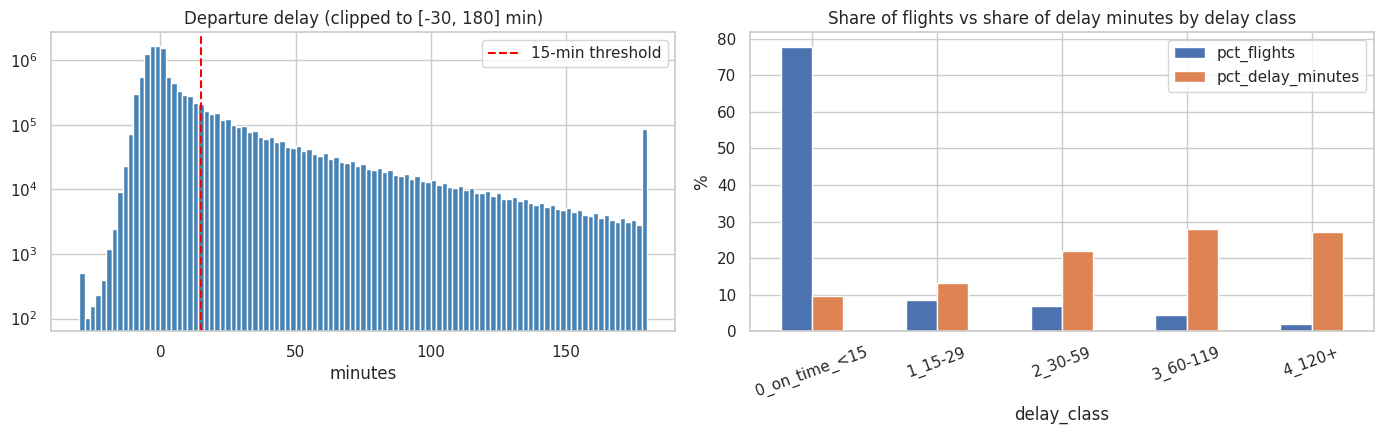


2) TIME PATTERNS
Delay rate % by scheduled hour:
             flights  delay_rate_pct  mean_delay_min_pos
sched_hour                                             
0             15681           16.40            9.260000
1              4179           11.25            7.020000
2               958            5.85            5.910000
3                 5           20.00           12.000000
4                 5            0.00            0.600000
5             35844            5.67            4.020000
6            601596            6.34            4.340000
7            744277            8.87            5.520000
8            866617           11.82            7.070000
9            831470           14.73            8.400000
10           776121           17.12            9.600000
11           770542           18.35           10.320000
12           723845           20.28           11.690000
13           775661           22.62           13.280000
14           731448           24.89           14.7300

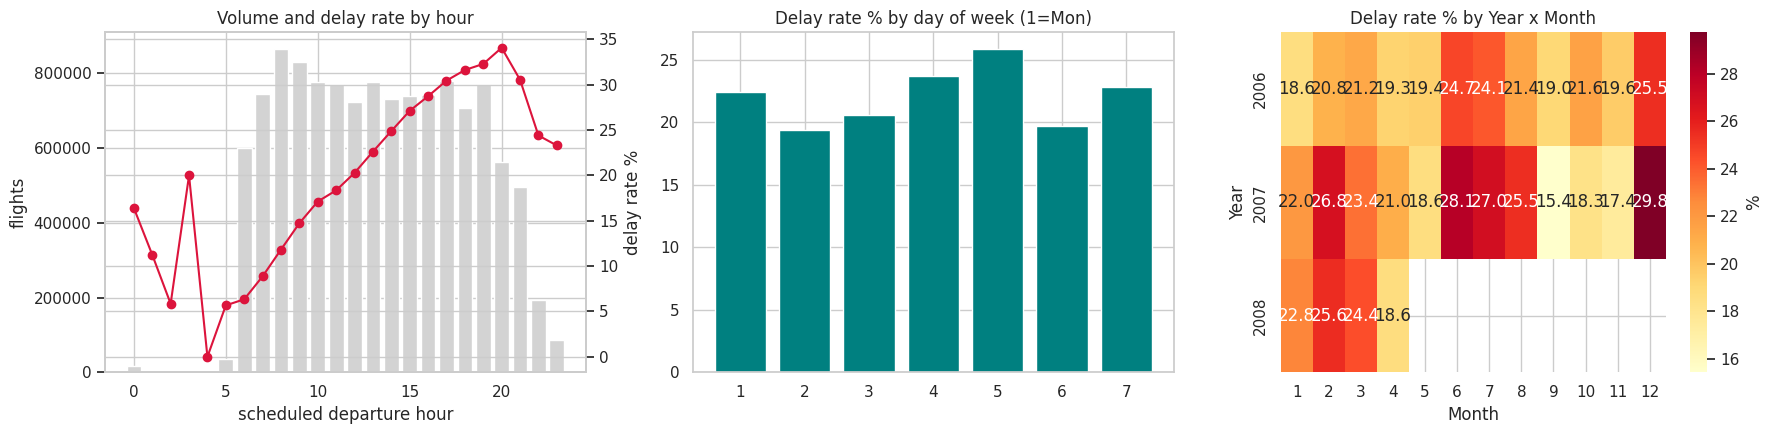


3) CARRIER, ORIGIN, DISTANCE
Carriers:
                flights  delay_rate_pct  mean_delay_min_pos
UniqueCarrier                                             
EV              349541           33.27           20.059999
MQ              759644           25.66           15.040000
YV              413424           24.38           17.020000
AA             1215403           24.31           15.640000
OH              384936           23.80           13.650000
UA              976769           23.43           15.950000
WN             1746105           23.22           12.140000
B6              304152           22.74           16.150000
AS              237595           22.37           13.100000
FL              454110           21.89           13.240000
XE              609827           21.56           14.530000
TZ               17515           21.54           15.910000
CO              624678           21.39           14.130000
US              937079           21.06           12.170000
OO             

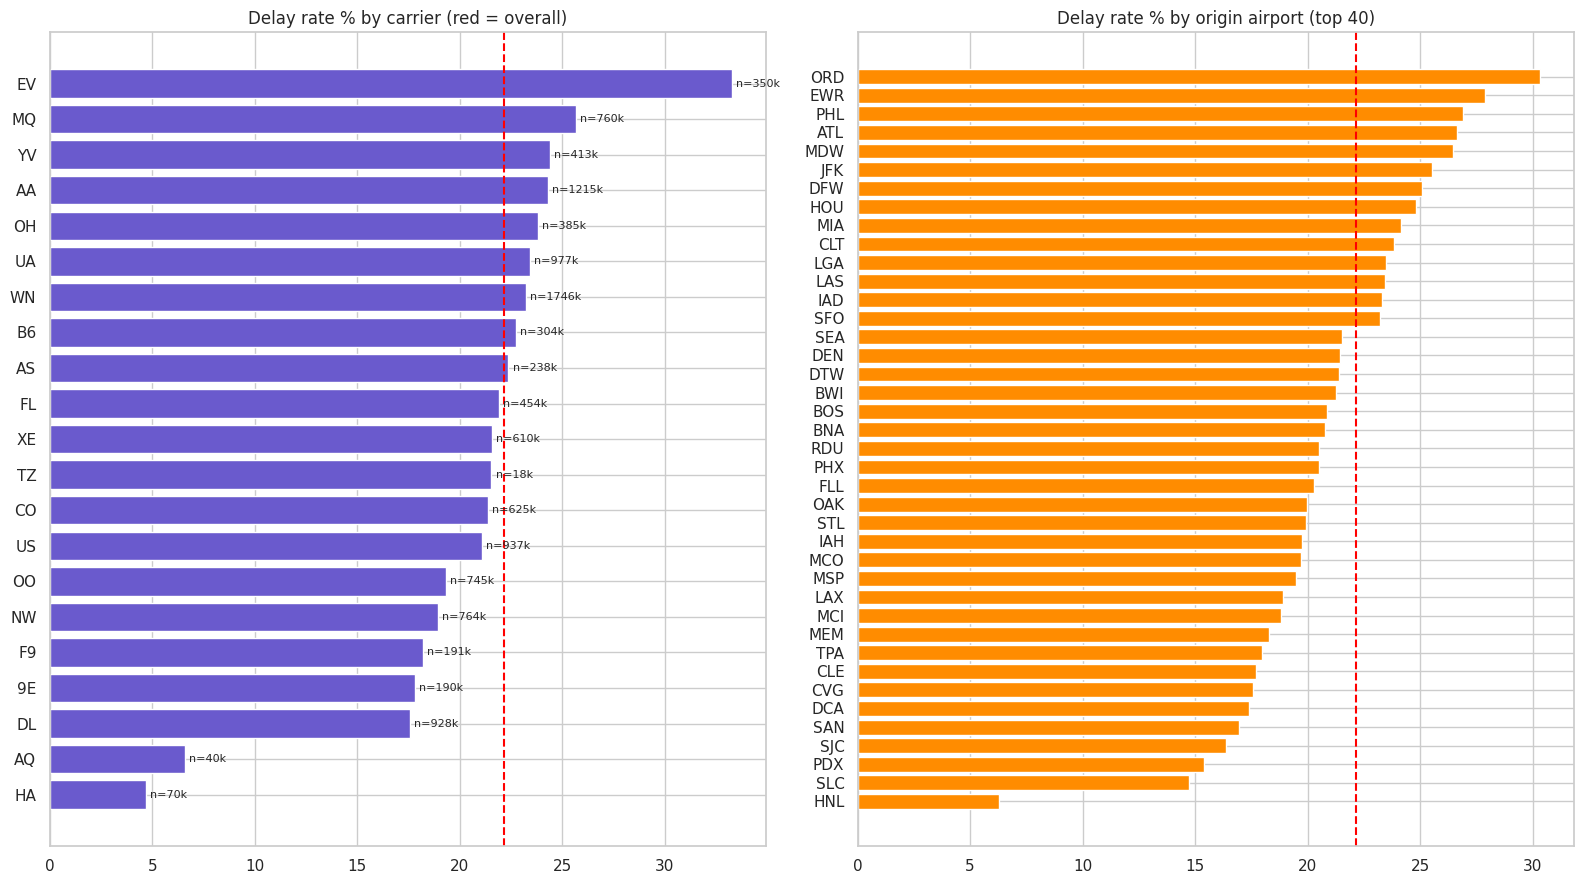


4) DELAY-CAUSE FIELDS (DESCRIPTIVE ONLY — NEVER MODEL FEATURES)
Cause fields populated | by ArrDelay>=15 (rows sum to 1):
cause_present  False  True 
ArrDelay>=15               
False          0.137  0.863
True           0.000  1.000

Cause fields populated | by DepDelay>=15 (is_delayed_15):
cause_present  False  True 
is_delayed_15              
0              0.124  0.876
1              0.023  0.977

NOTE: causes attribute ARRIVAL delay minutes, so they only loosely describe departure delay.

Share of attributed delay minutes by cause (%):
CarrierDelay         29.290001
WeatherDelay          5.600000
NASDelay             27.459999
SecurityDelay         0.200000
LateAircraftDelay    37.459999

Cause share % by Year:
       CarrierDelay  WeatherDelay  NASDelay  SecurityDelay  LateAircraftDelay
Year                                                                        
2006         28.84          5.72      28.0           0.24          37.189999
2007         29.58          5.67      27

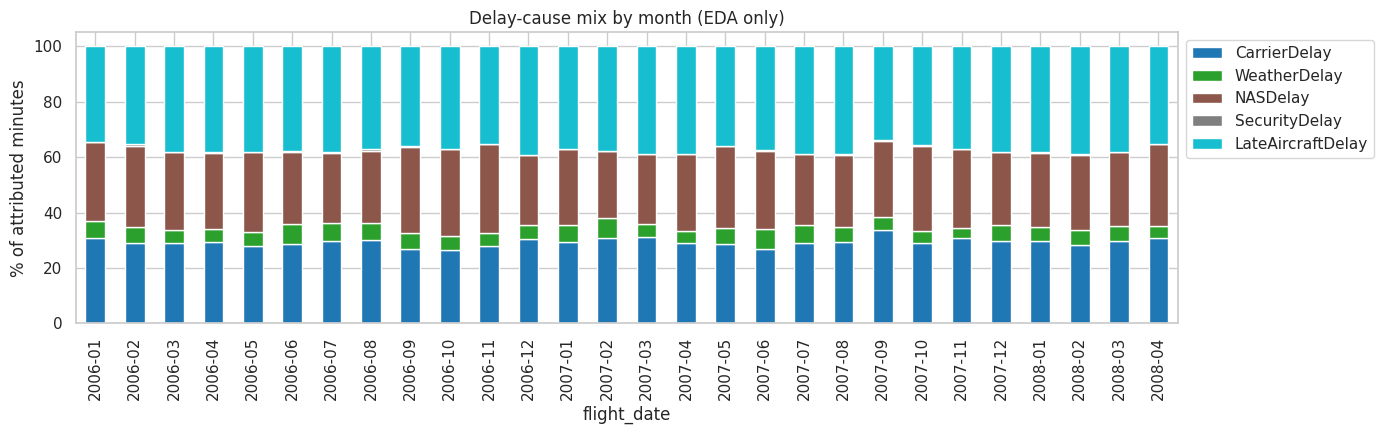


5) CANCELLATION / DIVERSION AUDIT
Cancelled: 241,931 (1.98%) | Diverted: 26,548 (0.22%)

Cancellation codes:
 CancellationCode
A_carrier     104398
B_weather      86323
C_NAS          51100
D_security       110

Monthly cancelled/diverted rate %:
 status       cancelled  diverted
flight_date                     
2006-01           1.63      0.22
2006-02           2.15      0.26
2006-03           1.19      0.17
2006-04           1.04      0.16
2006-05           1.11      0.19
2006-06           1.66      0.29
2006-07           1.70      0.30
2006-08           1.51      0.23
2006-09           1.64      0.19
2006-10           1.75      0.18
2006-11           1.58      0.18
2006-12           2.87      0.21
2007-01           2.31      0.18
2007-02           4.50      0.20
2007-03           2.63      0.18
2007-04           1.78      0.18
2007-05           1.06      0.20
2007-06           2.72      0.34
2007-07           2.05      0.31
2007-08           1.80      0.30
2007-09           1.04   

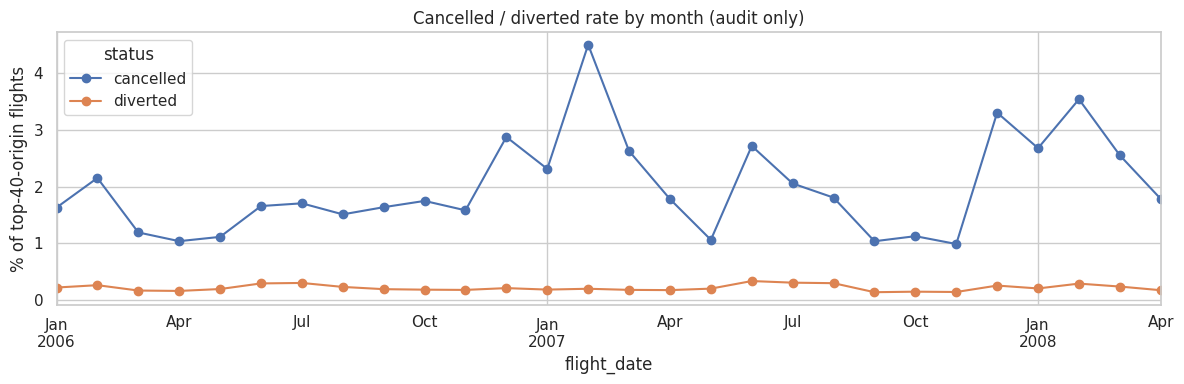


6) DATA-QUALITY GATES
DepDelay < -60 min: 116 | DepDelay >= 600 min: 1,388 | >= 1440: 11
CRSDepTime minutes>59: 0 | ==2400: 0 | >2400: 0
Distance <=0 or null: 0
CRSElapsedTime null: 0 | <=0: 0 | <15: 1 | >900: 0
FlightNum null: 0

Distinct tails: 5,899 | suspicious tail patterns (all zeros / len<4): ['0', '000000', 'HZO']
Flights with suspicious tails: 122
Top 10 tails by flight count:
 TailNum
N308SW    5352
N913DE    4773
N912DE    4729
N914DE    4700
N911DE    4696
N916DE    4645
N915DE    4641
N908DE    4536
N485HA    4513
N909DE    4505
Flights per tail:  {'count': 5899.0, 'mean': 2027.0, 'std': 957.0, 'min': 0.0, '5%': 109.0, '50%': 2168.0, '95%': 3549.1, 'max': 5352.0}

Legs per tail per day (quantiles): {0.5: 3.0, 0.9: 5.0, 0.99: 7.0, 0.999: 9.0, 1.0: 17.0}
Tail-days with > 10 legs: 365

Exact duplicate (date, carrier, flight, origin, dest, CRSDepTime) rows: 37 (0.0003%)

Assertions:
  split sizes: {'train': 7678164, 'val': 2624868, 'test': 1654311}
  TARGET_DERIVED_COLS reser

In [5]:
# ============================================================
# CELL 5 — EDA + data-quality gates (no feature engineering)
# ============================================================
import re

# ---- 0) Ensure frames exist (reload if the kernel was restarted) ----
if "model_df" not in globals() or "audit_df" not in globals():
    print("model_df/audit_df not in memory -> reloading from parquet")
    mp = PROCESSED_DIR / "model_base.parquet"
    ap_ = PROCESSED_DIR / "audit_cancel_divert.parquet"
    for p in (mp, ap_):
        if not p.exists():
            raise FileNotFoundError(f"{p} missing. Re-run CELL 4.")
    model_df = pd.read_parquet(mp)
    audit_df = pd.read_parquet(ap_)

need = ["flight_date", "Year", "Month", "DayOfWeek", "CRSDepTime", "UniqueCarrier", "FlightNum",
        "TailNum", "Origin", "Dest", "Distance", "CRSElapsedTime", "DepDelay", "ArrDelay",
        "dep_delay_minutes", "is_delayed_15", "split"]
miss = [c for c in need if c not in model_df.columns]
if miss:
    raise KeyError(f"model_df missing columns: {miss}")

# Outcome-derived columns: NEVER model features (used for EDA / subgroup analysis only)
TARGET_DERIVED_COLS = ["DepDelay", "dep_delay_minutes", "is_delayed_15",
                       "dep_delay_pos", "dep_delay_pos_cap300", "delay_class"]

DELAY_CLASS_LABELS = ["0_on_time_<15", "1_15-29", "2_30-59", "3_60-119", "4_120+"]

def add_eda_columns(df):
    df["sched_hour"] = ((df["CRSDepTime"].astype("int32") // 100) % 24).astype("int8")  # calendar-derived, allowed
    df["dep_delay_pos"] = df["dep_delay_minutes"].clip(lower=0).astype("float32")
    df["dep_delay_pos_cap300"] = df["dep_delay_minutes"].clip(lower=0, upper=300).astype("float32")
    df["delay_class"] = pd.cut(df["dep_delay_minutes"], bins=[-np.inf, 15, 30, 60, 120, np.inf],
                               labels=DELAY_CLASS_LABELS, right=False)
    return df

model_df = add_eda_columns(model_df)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(REPORTS_DIR / name, dpi=120, bbox_inches="tight")
    plt.show()

def rate_table(df, by):
    t = df.groupby(by, observed=True).agg(
        flights=("is_delayed_15", "size"),
        delay_rate_pct=("is_delayed_15", lambda s: s.mean() * 100),
        mean_delay_min_pos=("dep_delay_pos", "mean"),
    )
    t["delay_rate_pct"] = t["delay_rate_pct"].round(2)
    t["mean_delay_min_pos"] = t["mean_delay_min_pos"].round(2)
    return t

print("=" * 78)
print("1) TARGET AND DELAY-CLASS STRUCTURE")
print("=" * 78)
dc = model_df.groupby("delay_class", observed=True).agg(
    flights=("is_delayed_15", "size"), minutes=("dep_delay_pos", "sum"))
dc["pct_flights"] = (dc["flights"] / dc["flights"].sum() * 100).round(2)
dc["pct_delay_minutes"] = (dc["minutes"] / dc["minutes"].sum() * 100).round(2)
print(dc.drop(columns="minutes").to_string())
dc.to_csv(REPORTS_DIR / "delay_class_summary.csv")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].hist(model_df["dep_delay_minutes"].clip(-30, 180), bins=105, color="steelblue")
ax[0].axvline(DELAY_THRESHOLD_MIN, color="red", ls="--", label="15-min threshold")
ax[0].set_title("Departure delay (clipped to [-30, 180] min)")
ax[0].set_xlabel("minutes"); ax[0].set_yscale("log"); ax[0].legend()
dc[["pct_flights", "pct_delay_minutes"]].plot.bar(ax=ax[1], rot=20)
ax[1].set_title("Share of flights vs share of delay minutes by delay class")
ax[1].set_ylabel("%")
save_fig("eda_target_distribution.png")

print("\n" + "=" * 78)
print("2) TIME PATTERNS")
print("=" * 78)
hour_t = rate_table(model_df, "sched_hour")
dow_t = rate_table(model_df, "DayOfWeek")
ym = (model_df.groupby(["Year", "Month"], observed=True)["is_delayed_15"].mean() * 100).unstack("Month").round(2)
print("Delay rate % by scheduled hour:\n", hour_t.to_string())
print("\nDelay rate % by DayOfWeek (1=Mon):\n", dow_t.to_string())
print("\nDelay rate % by Year x Month:\n", ym.to_string())
hour_t.to_csv(REPORTS_DIR / "rate_by_hour.csv"); dow_t.to_csv(REPORTS_DIR / "rate_by_dow.csv")
ym.to_csv(REPORTS_DIR / "rate_by_year_month.csv")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].bar(hour_t.index, hour_t["flights"], color="lightgray")
ax[0].set_ylabel("flights"); ax[0].set_xlabel("scheduled departure hour")
ax0b = ax[0].twinx()
ax0b.plot(hour_t.index, hour_t["delay_rate_pct"], color="crimson", marker="o")
ax0b.set_ylabel("delay rate %"); ax[0].set_title("Volume and delay rate by hour")
ax[1].bar(dow_t.index.astype(str), dow_t["delay_rate_pct"], color="teal")
ax[1].set_title("Delay rate % by day of week (1=Mon)"); ax[1].set_ylim(0, None)
sns.heatmap(ym, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax[2], cbar_kws={"label": "%"})
ax[2].set_title("Delay rate % by Year x Month")
save_fig("eda_time_patterns.png")

print("\n" + "=" * 78)
print("3) CARRIER, ORIGIN, DISTANCE")
print("=" * 78)
car_t = rate_table(model_df, "UniqueCarrier").sort_values("delay_rate_pct", ascending=False)
org_t = rate_table(model_df, "Origin").sort_values("delay_rate_pct", ascending=False)
dist_bins = [0, 250, 500, 750, 1000, 1500, 2000, 3000, 10000]
model_df["_dist_bin"] = pd.cut(model_df["Distance"], bins=dist_bins)
dist_t = rate_table(model_df, "_dist_bin")
model_df.drop(columns="_dist_bin", inplace=True)
print("Carriers:\n", car_t.to_string())
print("\nOrigins (top 10 / bottom 10 by delay rate):")
print(pd.concat([org_t.head(10), org_t.tail(10)]).to_string())
print("\nDistance bins:\n", dist_t.to_string())
car_t.to_csv(REPORTS_DIR / "rate_by_carrier.csv"); org_t.to_csv(REPORTS_DIR / "rate_by_origin.csv")
dist_t.to_csv(REPORTS_DIR / "rate_by_distance.csv")

fig, ax = plt.subplots(1, 2, figsize=(16, 9))
c_sorted = car_t.sort_values("delay_rate_pct")
ax[0].barh(c_sorted.index.astype(str), c_sorted["delay_rate_pct"], color="slateblue")
for i, (r, n) in enumerate(zip(c_sorted["delay_rate_pct"], c_sorted["flights"])):
    ax[0].text(r + 0.2, i, f"n={n/1000:.0f}k", va="center", fontsize=8)
ax[0].axvline(model_df["is_delayed_15"].mean() * 100, color="red", ls="--")
ax[0].set_title("Delay rate % by carrier (red = overall)")
o_sorted = org_t.sort_values("delay_rate_pct")
ax[1].barh(o_sorted.index.astype(str), o_sorted["delay_rate_pct"], color="darkorange")
ax[1].axvline(model_df["is_delayed_15"].mean() * 100, color="red", ls="--")
ax[1].set_title("Delay rate % by origin airport (top 40)")
save_fig("eda_carrier_origin.png")

print("\n" + "=" * 78)
print("4) DELAY-CAUSE FIELDS (DESCRIPTIVE ONLY — NEVER MODEL FEATURES)")
print("=" * 78)
cause_cols = [c for c in EDA_ONLY_FIELDS if c in model_df.columns]
cause_present = model_df[cause_cols].notna().all(axis=1)
arr15 = model_df["ArrDelay"] >= 15
print("Cause fields populated | by ArrDelay>=15 (rows sum to 1):")
print(pd.crosstab(arr15.rename("ArrDelay>=15"), cause_present.rename("cause_present"), normalize="index").round(3).to_string())
print("\nCause fields populated | by DepDelay>=15 (is_delayed_15):")
print(pd.crosstab(model_df["is_delayed_15"], cause_present.rename("cause_present"), normalize="index").round(3).to_string())
print("\nNOTE: causes attribute ARRIVAL delay minutes, so they only loosely describe departure delay.")

cs = model_df.loc[cause_present, cause_cols].sum()
print("\nShare of attributed delay minutes by cause (%):")
print((cs / cs.sum() * 100).round(2).to_string())
by_year = model_df.loc[cause_present].groupby("Year")[cause_cols].sum()
print("\nCause share % by Year:\n", by_year.div(by_year.sum(axis=1), axis=0).mul(100).round(2).to_string())

mc = model_df.loc[cause_present].groupby(model_df.loc[cause_present, "flight_date"].dt.to_period("M"))[cause_cols].sum()
mc = mc.div(mc.sum(axis=1), axis=0) * 100
mc.plot(kind="bar", stacked=True, figsize=(14, 4.5), colormap="tab10")
plt.ylabel("% of attributed minutes"); plt.title("Delay-cause mix by month (EDA only)")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
save_fig("eda_delay_causes.png")
mc.round(2).to_csv(REPORTS_DIR / "delay_cause_mix_by_month.csv")

print("\n" + "=" * 78)
print("5) CANCELLATION / DIVERSION AUDIT")
print("=" * 78)
total_top40 = len(model_df) + len(audit_df)
print(f"Cancelled: {(audit_df['status']=='cancelled').sum():,} ({(audit_df['status']=='cancelled').sum()/total_top40*100:.2f}%) | "
      f"Diverted: {(audit_df['status']=='diverted').sum():,} ({(audit_df['status']=='diverted').sum()/total_top40*100:.2f}%)")
canc = audit_df.loc[audit_df["status"] == "cancelled"]
code_map = {"A": "A_carrier", "B": "B_weather", "C": "C_NAS", "D": "D_security"}
codes = canc["CancellationCode"].astype("object").fillna("missing").map(lambda x: code_map.get(x, x))
print("\nCancellation codes:\n", codes.value_counts().to_string())

m_all = model_df.groupby(model_df["flight_date"].dt.to_period("M")).size()
a_m = audit_df.groupby([audit_df["flight_date"].dt.to_period("M"), "status"], observed=True).size().unstack(fill_value=0)
den = m_all.add(a_m.sum(axis=1), fill_value=0)
a_rate = a_m.div(den, axis=0) * 100
print("\nMonthly cancelled/diverted rate %:\n", a_rate.round(2).to_string())
a_rate.round(3).to_csv(REPORTS_DIR / "audit_monthly_rates.csv")

car_all = model_df.groupby("UniqueCarrier", observed=True).size().add(
    audit_df.groupby("UniqueCarrier", observed=True).size(), fill_value=0)
car_canc = (canc.groupby("UniqueCarrier", observed=True).size().reindex(car_all.index).fillna(0) / car_all * 100).round(2)
print("\nCancellation rate % by carrier (top 10):\n", car_canc.sort_values(ascending=False).head(10).to_string())
a_rate.plot(figsize=(12, 4), marker="o"); plt.ylabel("% of top-40-origin flights")
plt.title("Cancelled / diverted rate by month (audit only)")
save_fig("eda_audit_monthly.png")

print("\n" + "=" * 78)
print("6) DATA-QUALITY GATES")
print("=" * 78)
dd = model_df["dep_delay_minutes"]
print(f"DepDelay < -60 min: {(dd < -60).sum():,} | DepDelay >= 600 min: {(dd >= 600).sum():,} | >= 1440: {(dd >= 1440).sum():,}")
crs = model_df["CRSDepTime"].astype("int32")
print(f"CRSDepTime minutes>59: {((crs % 100) > 59).sum():,} | ==2400: {(crs == 2400).sum():,} | >2400: {(crs > 2400).sum():,}")
print(f"Distance <=0 or null: {((model_df['Distance'] <= 0) | model_df['Distance'].isna()).sum():,}")
print(f"CRSElapsedTime null: {model_df['CRSElapsedTime'].isna().sum():,} | <=0: {(model_df['CRSElapsedTime'] <= 0).sum():,} | "
      f"<15: {(model_df['CRSElapsedTime'] < 15).sum():,} | >900: {(model_df['CRSElapsedTime'] > 900).sum():,}")
print(f"FlightNum null: {model_df['FlightNum'].isna().sum():,}")

tails = model_df["TailNum"].astype("category")
cats = [str(c) for c in tails.cat.categories]
suspicious = [t for t in cats if re.fullmatch(r"0+", t) or len(t) < 4]
print(f"\nDistinct tails: {len(cats):,} | suspicious tail patterns (all zeros / len<4): {suspicious[:15]}")
print(f"Flights with suspicious tails: {int(tails.isin(suspicious).sum()):,}")
tail_counts = tails.value_counts()
print("Top 10 tails by flight count:\n", tail_counts.head(10).to_string())
print("Flights per tail: ", tail_counts.describe(percentiles=[.05, .5, .95]).round(1).to_dict())

tpd = model_df.groupby(["TailNum", "flight_date"], observed=True).size()
print("\nLegs per tail per day (quantiles):", tpd.quantile([.5, .9, .99, .999, 1.0]).to_dict())
print(f"Tail-days with > 10 legs: {(tpd > 10).sum():,}")
del tpd

dup_key = pd.DataFrame({
    "d": (model_df["flight_date"] - MODEL_START).dt.days.astype("int16"),
    "c": model_df["UniqueCarrier"].astype("category").cat.codes,
    "f": model_df["FlightNum"].fillna(-1).astype("int32"),
    "o": model_df["Origin"].astype("category").cat.codes,
    "de": model_df["Dest"].astype("category").cat.codes,
    "t": model_df["CRSDepTime"],
})
n_dup = int(dup_key.duplicated().sum())
print(f"\nExact duplicate (date, carrier, flight, origin, dest, CRSDepTime) rows: {n_dup:,} ({n_dup/len(model_df)*100:.4f}%)")
del dup_key
gc.collect()

print("\nAssertions:")
assert set(LEAKY_FIELDS).isdisjoint(set()), "sanity"
print("  split sizes:", model_df["split"].value_counts().to_dict())
print("  TARGET_DERIVED_COLS reserved (never features):", TARGET_DERIVED_COLS)
print("\nModel_df memory:", human_size(model_df.memory_usage(deep=True).sum()))


In [6]:

MIN_SCHED_TURN_MIN = 20
MAX_SCHED_TURN_MIN = 360
MAX_LEGS_PER_TAIL_DAY = 10
MAX_ABS_TZ_MIN = 360
INVALID_TAIL_TOKENS = {"UNKNOW", "UNKNOWN", "NA", "NAN", "NONE"}

STATUS = [
    "invalid_tail", "no_previous_leg", "ambiguous_duplicate", "implausible_tail_day",
    "invalid_schedule_fields", "prev_cancelled_or_diverted", "discontinuous_route",
    "gap_too_short", "gap_too_long", "prior_arrives_after_sched_dep", "ok",
]
OK_CODE = STATUS.index("ok")
LATE_CODE = STATUS.index("prior_arrives_after_sched_dep")

ROTATION_FEATURE_COLS = ["prior_leg_arrival_delay", "sched_turn_min"]
DIAGNOSTIC_ONLY_COLS = ["prior_leg_status"]  # for analysis only, never a model feature

RAW_DIR = PROCESSED_DIR / "raw_subset"
RAW_FILES = sorted(RAW_DIR.glob("flights_*.parquet"))
if len(RAW_FILES) != 3:
    raise FileNotFoundError(f"Expected 3 raw parquet files in {RAW_DIR}, found {len(RAW_FILES)}. Re-run CELL 3.")

if "model_df" not in globals():
    print("model_df not in memory -> reloading model_base.parquet")
    model_df = pd.read_parquet(PROCESSED_DIR / "model_base.parquet")

# ------------------------------------------------------------
# 1) Load ALL raw rows (all origins, incl. cancelled/diverted) with only the needed columns
# ------------------------------------------------------------
raw_cols = ["row_id", "flight_date", "CRSDepTime", "CRSArrTime", "CRSElapsedTime", "ArrDelay",
            "TailNum", "Origin", "Dest", "Cancelled", "Diverted"]
tbl = pa.concat_tables([pq.read_table(p, columns=raw_cols) for p in RAW_FILES])
raw = tbl.to_pandas(categories=["TailNum", "Origin", "Dest"])
del tbl
gc.collect()
n = len(raw)
print(f"Raw rows loaded: {n:,} | memory: {human_size(raw.memory_usage(deep=True).sum())}")

# Common airport code space for Origin and Dest (needed for continuity check)
airports = pd.Index(sorted(set(raw["Origin"].cat.categories) | set(raw["Dest"].cat.categories)))
def to_airport_code(cat_series):
    cats_map = airports.get_indexer(cat_series.cat.categories)
    codes = cat_series.cat.codes.to_numpy()
    return np.where(codes >= 0, cats_map[np.where(codes >= 0, codes, 0)], -1).astype(np.int16)
origin_code = to_airport_code(raw["Origin"])
dest_code = to_airport_code(raw["Dest"])

# Tail codes + invalid-tail flag (decided at category level)
tail_cats = raw["TailNum"].cat.categories
tail_codes = raw["TailNum"].cat.codes.to_numpy()
tc_str = pd.Series(tail_cats.astype(str))
bad_cat = (tc_str.str.len() < 4) | tc_str.str.fullmatch(r"0+") | tc_str.str.upper().isin(INVALID_TAIL_TOKENS)
tail_bad = (tail_codes < 0) | bad_cat.to_numpy()[np.where(tail_codes >= 0, tail_codes, 0)]
tail_eff = np.where(tail_bad, -1, tail_codes).astype(np.int32)
print(f"Rows with invalid/placeholder tail: {tail_bad.sum():,} ({tail_bad.mean() * 100:.2f}%)")

day_idx = (raw["flight_date"].to_numpy().astype("datetime64[D]") - np.datetime64("2006-01-01")).astype("int32")
crsdep = raw["CRSDepTime"].to_numpy().astype(np.int32)
crsarr = raw["CRSArrTime"].to_numpy().astype(np.int32)
elapsed = raw["CRSElapsedTime"].to_numpy().astype(np.float64)
arr_delay = raw["ArrDelay"].to_numpy().astype(np.float64)
canc = raw["Cancelled"].to_numpy() == 1
done = (~canc) & (raw["Diverted"].to_numpy() == 0) & np.isfinite(arr_delay)
row_id = raw["row_id"].to_numpy().astype(np.int64)
del raw
gc.collect()

# ------------------------------------------------------------
# 2) Absolute scheduled times in minutes (local clock of the flight's origin)
# ------------------------------------------------------------
def hhmm_to_min(x):
    return (x // 100) * 60 + (x % 100), ((x % 100) <= 59) & ((x // 100) <= 24)

dep_clock, dep_ok = hhmm_to_min(crsdep)
arr_clock, arr_ok = hhmm_to_min(crsarr)
elapsed_ok = np.isfinite(elapsed) & (elapsed > 0)
elapsed_i = np.where(elapsed_ok, np.rint(elapsed), 0).astype(np.int32)

# Clock offset (destination clock minus origin clock), mapped to [-720, 720)
tz = ((arr_clock - dep_clock - elapsed_i + 720) % 1440) - 720
fields_ok = dep_ok & arr_ok & elapsed_ok
tz_ok = (tz % 60 == 0) & (np.abs(tz) <= MAX_ABS_TZ_MIN)
time_ok = fields_ok & tz_ok

dep_abs = day_idx.astype(np.int64) * 1440 + dep_clock
sched_arr_abs = dep_abs + elapsed_i + tz           # on the DESTINATION's clock
act_arr_abs = np.where(done, sched_arr_abs + np.nan_to_num(arr_delay), np.nan)

print("\n" + "=" * 78)
print("TIME-ZONE OFFSET AUDIT (inferred destination-minus-origin clock offset, minutes)")
print("=" * 78)
print(f"Rows with valid HHMM + elapsed fields: {fields_ok.mean() * 100:.2f}%")
print(f"Rows where offset is a whole-hour value within +/-{MAX_ABS_TZ_MIN} min: {time_ok.mean() * 100:.2f}% of all rows "
      f"({tz_ok[fields_ok].mean() * 100:.2f}% of rows with valid fields)")
print((pd.Series(tz[fields_ok]).value_counts(normalize=True).head(12) * 100).round(3).rename("pct_rows").to_string())

# ------------------------------------------------------------
# 3) Sort by (tail, scheduled departure, row_id) and link to the previous leg
# ------------------------------------------------------------
order = np.lexsort((row_id, dep_abs, tail_eff))
arrs = {"row_id": row_id, "day": day_idx, "crsdep": crsdep, "dep_abs": dep_abs, "sarr": sched_arr_abs,
        "aarr": act_arr_abs, "arrdelay": arr_delay, "tail": tail_eff, "origin": origin_code, "dest": dest_code,
        "done": done, "canc": canc, "timeok": time_ok, "depok": dep_ok}
A = {k: v[order] for k, v in arrs.items()}
del arrs, order, row_id, day_idx, crsdep, crsarr, elapsed, elapsed_i, arr_delay, dep_clock, arr_clock
del dep_abs, sched_arr_abs, act_arr_abs, tz, tail_eff, tail_codes, origin_code, dest_code, done, canc, time_ok, dep_ok
gc.collect()

def prev1(a, fill):
    out = np.empty_like(a)
    out[0] = fill
    out[1:] = a[:-1]
    return out

tc_s = A["tail"]
valid_tail = tc_s >= 0
same = np.zeros(n, dtype=bool)
same[1:] = (tc_s[1:] == tc_s[:-1]) & (tc_s[1:] >= 0)

# Tail-days with too many (non-cancelled) legs are physically implausible
key = tc_s.astype(np.int64) * 2048 + A["day"]
uk, cnt = np.unique(key[valid_tail & ~A["canc"]], return_counts=True)
over_keys = uk[cnt > MAX_LEGS_PER_TAIL_DAY]
overload = np.isin(key, over_keys) & valid_tail
print("\n" + "=" * 78)
print("TAIL-DAY PLAUSIBILITY")
print("=" * 78)
print(f"Tail-days with > {MAX_LEGS_PER_TAIL_DAY} legs: {len(over_keys):,} | rows on those tail-days: {overload.sum():,}")
del key, uk, cnt, over_keys

p_dep = prev1(A["dep_abs"], 0)
p_sarr = prev1(A["sarr"], 0)
p_aarr = prev1(A["aarr"], np.nan)
p_arrdelay = prev1(A["arrdelay"], np.nan)
p_dest = prev1(A["dest"], -1)
p_done = prev1(A["done"], False)
p_timeok = prev1(A["timeok"], False)
p_over = prev1(overload, False)

tie = same & (A["dep_abs"] == p_dep)          # two legs of one tail with identical scheduled departure
ambiguous = tie | (same & prev1(tie, False))  # current leg or its predecessor is part of a tie
gap = A["dep_abs"] - p_sarr                   # scheduled turnaround (cur sched dep - prev sched arrival)

conds = [
    ~valid_tail,                                   # invalid_tail
    ~same,                                         # no_previous_leg
    ambiguous,                                     # ambiguous_duplicate
    overload | p_over,                             # implausible_tail_day
    (~A["depok"]) | (~p_timeok),                   # invalid_schedule_fields
    ~p_done,                                       # prev_cancelled_or_diverted
    p_dest != A["origin"],                         # discontinuous_route
    gap < MIN_SCHED_TURN_MIN,                      # gap_too_short (includes negative gaps)
    gap > MAX_SCHED_TURN_MIN,                      # gap_too_long
    p_aarr > A["dep_abs"],                         # prior_arrives_after_sched_dep
]
status = np.select(conds, list(range(len(conds))), default=OK_CODE).astype(np.int8)
ok = status == OK_CODE
late = status == LATE_CODE

prior_delay = np.where(ok, p_arrdelay, np.nan).astype(np.float32)
sched_turn = np.where(ok | late, gap, np.nan).astype(np.float32)

# Hard leakage / consistency assertions on every linked row
assert (tc_s[ok] == prev1(tc_s, -2)[ok]).all(), "linked rows must share the tail"
assert (p_dep[ok] <= A["dep_abs"][ok]).all(), "previous leg must be scheduled earlier"
assert (p_aarr[ok] <= A["dep_abs"][ok]).all(), "previous leg must have ARRIVED before scheduled departure"
assert (p_dest[ok] == A["origin"][ok]).all(), "previous destination must equal current origin"
assert np.isfinite(prior_delay[ok]).all()
print("\nLeakage/consistency assertions passed for", f"{ok.sum():,}", "linked rows.")

print("\n" + "=" * 78)
print("LINK STATUS — ALL RAW ROWS (all origins, incl. cancelled/diverted)")
print("=" * 78)
st_all = pd.DataFrame({"rows": np.bincount(status, minlength=len(STATUS))}, index=STATUS)
st_all["pct"] = (st_all["rows"] / n * 100).round(2)
print(st_all.to_string())
st_all.to_csv(REPORTS_DIR / "rotation_status_all_raw.csv")

# ------------------------------------------------------------
# 4) Manual spot-check of one aircraft-day (eyeball the chain)
# ------------------------------------------------------------
print("\n" + "=" * 78)
print("SPOT CHECK: one tail on one day, legs in scheduled order")
print("=" * 78)
spot_name = "N308SW" if "N308SW" in set(tail_cats) else str(tail_cats[0])
code = int(tail_cats.get_loc(spot_name))
t_rows = np.flatnonzero(tc_s == code)
dcount = pd.Series(A["day"][t_rows]).value_counts().sort_index()
cand = dcount[(dcount >= 5) & (dcount <= 8)]
d_pick = int(cand.index[len(cand) // 2]) if len(cand) else int(dcount.index[0])
idx = t_rows[A["day"][t_rows] == d_pick]
spot = pd.DataFrame({
    "date": pd.Timestamp("2006-01-01") + pd.to_timedelta(A["day"][idx], unit="D"),
    "from": airports[A["origin"][idx]].to_numpy(), "to": airports[A["dest"][idx]].to_numpy(),
    "crs_dep": A["crsdep"][idx], "own_arr_delay": A["arrdelay"][idx],
    "status": np.array(STATUS)[status[idx]], "prior_leg_arr_delay": prior_delay[idx],
    "sched_turn_min": sched_turn[idx],
})
print(f"Tail {spot_name}:")
print(spot.to_string(index=False))

# ------------------------------------------------------------
# 5) Package results by row_id and attach to model_df
# ------------------------------------------------------------
res = pd.DataFrame({
    "prior_leg_arrival_delay": prior_delay,
    "sched_turn_min": sched_turn,
    "prior_leg_status": pd.Categorical.from_codes(status, categories=STATUS),
}, index=pd.Index(A["row_id"], name="row_id"))
del A, p_dep, p_sarr, p_aarr, p_arrdelay, p_dest, p_done, p_timeok, p_over, tie, ambiguous, gap, conds
del status, ok, late, prior_delay, sched_turn, same, valid_tail, overload, tc_s
gc.collect()

rot_model = res.reindex(model_df["row_id"].to_numpy())
assert rot_model["prior_leg_status"].notna().all(), "some model rows not found in raw chain"
for c in ROTATION_FEATURE_COLS:
    model_df[c] = rot_model[c].to_numpy()
model_df["prior_leg_status"] = rot_model["prior_leg_status"].values
del res, rot_model
gc.collect()

model_df["sched_hour"] = ((model_df["CRSDepTime"].astype("int32") // 100) % 24).astype("int8")
has_prior = model_df["prior_leg_arrival_delay"].notna()

print("\n" + "=" * 78)
print("MODEL ROWS — COVERAGE AND STATUS")
print("=" * 78)
print("Share of model rows with prior_leg_arrival_delay (%), by split:")
print((has_prior.groupby(model_df["split"], observed=True).mean() * 100).round(2).to_string())
print("\nLink status (% of rows within split):")
print((pd.crosstab(model_df["prior_leg_status"], model_df["split"], normalize="columns") * 100).round(2).to_string())
print("\nCoverage by scheduled hour:")
cov_hour = pd.DataFrame({"flights": model_df.groupby("sched_hour", observed=True).size(),
                         "pct_with_prior": (has_prior.groupby(model_df["sched_hour"], observed=True).mean() * 100).round(1)})
print(cov_hour.to_string())
print("\nsched_turn_min where linked (ok rows):")
print(model_df.loc[model_df["prior_leg_status"] == "ok", "sched_turn_min"]
      .describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1).to_string())
print("\nprior_leg_arrival_delay where present:")
print(model_df["prior_leg_arrival_delay"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1).to_string())

# ------------------------------------------------------------
# 6) Signal sanity check on TRAIN ONLY (validation/test untouched)
# ------------------------------------------------------------
print("\n" + "=" * 78)
print("TRAIN-ONLY SIGNAL CHECK")
print("=" * 78)
tr = model_df.loc[model_df["split"] == "train", ["prior_leg_arrival_delay", "prior_leg_status", "is_delayed_15"]].copy()
tr["prior_bin"] = pd.cut(tr["prior_leg_arrival_delay"], bins=[-np.inf, -15, 0, 15, 30, 60, 120, np.inf])
sig = tr.groupby("prior_bin", observed=True)["is_delayed_15"].agg(flights="size", delay_rate_pct=lambda s: s.mean() * 100)
sig["delay_rate_pct"] = sig["delay_rate_pct"].round(2)
print("Delay rate by prior-leg arrival delay bin (train):")
print(sig.to_string())
print("\nDelay rate by link status (train):")
bys = tr.groupby("prior_leg_status", observed=True)["is_delayed_15"].agg(flights="size", delay_rate_pct=lambda s: s.mean() * 100)
bys["delay_rate_pct"] = bys["delay_rate_pct"].round(2)
print(bys.to_string())
tr_ok = tr.dropna(subset=["prior_leg_arrival_delay"])
print(f"\nStand-alone ROC-AUC of prior_leg_arrival_delay on linked train rows: "
      f"{roc_auc_score(tr_ok['is_delayed_15'], tr_ok['prior_leg_arrival_delay']):.4f} (n={len(tr_ok):,})")
del tr, tr_ok
gc.collect()

# ------------------------------------------------------------
# 7) Persist
# ------------------------------------------------------------
model_df[["row_id"] + ROTATION_FEATURE_COLS + DIAGNOSTIC_ONLY_COLS].to_parquet(
    PROCESSED_DIR / "rotation_features.parquet", index=False, compression="zstd")
crosstab_out = pd.crosstab(model_df["prior_leg_status"], model_df["split"])
crosstab_out.to_csv(REPORTS_DIR / "rotation_status_model_rows.csv")
cov_hour.to_csv(REPORTS_DIR / "rotation_coverage_by_hour.csv")
with open(REPORTS_DIR / "rotation_params.json", "w") as f:
    json.dump({"MIN_SCHED_TURN_MIN": MIN_SCHED_TURN_MIN, "MAX_SCHED_TURN_MIN": MAX_SCHED_TURN_MIN,
               "MAX_LEGS_PER_TAIL_DAY": MAX_LEGS_PER_TAIL_DAY, "MAX_ABS_TZ_MIN": MAX_ABS_TZ_MIN,
               "feature_cols": ROTATION_FEATURE_COLS, "diagnostic_only_cols": DIAGNOSTIC_ONLY_COLS}, f, indent=2)
print("\nSaved:", PROCESSED_DIR / "rotation_features.parquet")
print("model_df memory:", human_size(model_df.memory_usage(deep=True).sum()))

Raw rows loaded: 16,984,354 | memory: 583.59 MB
Rows with invalid/placeholder tail: 242,070 (1.43%)

TIME-ZONE OFFSET AUDIT (inferred destination-minus-origin clock offset, minutes)
Rows with valid HHMM + elapsed fields: 99.99%
Rows where offset is a whole-hour value within +/-360 min: 99.99% of all rows (100.00% of rows with valid fields)
 0      56.596
-60     15.012
 60     14.979
-120     4.082
 120     4.073
 180     2.556
-180     2.544
 240     0.035
 300     0.034
-300     0.034
-240     0.033
 360     0.010

TAIL-DAY PLAUSIBILITY
Tail-days with > 10 legs: 33,722 | rows on those tail-days: 423,369

Leakage/consistency assertions passed for 11,353,902 linked rows.

LINK STATUS — ALL RAW ROWS (all origins, incl. cancelled/diverted)
                                   rows    pct
invalid_tail                     242070   1.43
no_previous_leg                    5899   0.03
ambiguous_duplicate                6623   0.04
implausible_tail_day             437354   2.58
invalid_schedule_

In [8]:
# CELL 7 — Historical delay-rate features

import gc
import numpy as np
import pandas as pd

if "model_df" not in globals():
    model_path = PROCESSED_DIR / "model_base.parquet"
    if not model_path.exists():
        raise FileNotFoundError(f"Missing {model_path}. Re-run CELL 4.")
    model_df = pd.read_parquet(model_path)

rotation_path = PROCESSED_DIR / "rotation_features.parquet"
if not rotation_path.exists():
    raise FileNotFoundError(f"Missing {rotation_path}. Re-run CELL 6.")

rotation_df = pd.read_parquet(rotation_path)

required = [
    "row_id", "flight_date", "CRSDepTime", "UniqueCarrier",
    "Origin", "Dest", "is_delayed_15", "split"
]
missing = [c for c in required if c not in model_df.columns]
if missing:
    raise KeyError(f"model_df is missing required columns: {missing}")

if not model_df["row_id"].is_unique:
    raise ValueError("row_id must be unique.")
if not rotation_df["row_id"].is_unique:
    raise ValueError("rotation_features.parquet has duplicate row_id values.")

GROUPS = {
    "carrier": ["UniqueCarrier"],
    "origin": ["Origin"],
    "route": ["Origin", "Dest"],
    "sched_hour": ["sched_hour"],
}
HISTORICAL_FEATURES = [f"hist_{name}_delay_rate" for name in GROUPS]
HISTORICAL_COUNTS = [f"hist_{name}_count" for name in GROUPS]
ROTATION_FEATURES = ["prior_leg_arrival_delay", "sched_turn_min"]

old_columns = [
    "sched_hour", "month_start", "_row_pos",
    *HISTORICAL_FEATURES, *HISTORICAL_COUNTS,
]
for col in ROTATION_FEATURES:
    old_columns.extend([col, f"{col}_x", f"{col}_y"])
model_df.drop(columns=old_columns, errors="ignore", inplace=True)

rotation_predictors = rotation_df[["row_id", *ROTATION_FEATURES]].copy()
before_ids = model_df["row_id"].to_numpy(copy=True)

model_df = model_df.merge(
    rotation_predictors,
    on="row_id",
    how="left",
    validate="one_to_one",
    sort=False,
)
if len(model_df) != len(before_ids) or not np.array_equal(
    model_df["row_id"].to_numpy(), before_ids
):
    raise AssertionError("Rotation-feature join changed row count or order.")

model_df["flight_date"] = pd.to_datetime(model_df["flight_date"])
model_df["sched_hour"] = (
    model_df["CRSDepTime"].astype("int32").floordiv(100).mod(24).astype("int8")
)
model_df["month_start"] = (
    model_df["flight_date"].dt.to_period("M").dt.to_timestamp()
)
model_df["_row_pos"] = np.arange(len(model_df), dtype="int64")

FALLBACK_RATE = 0.20
MIN_HISTORY_COUNT = 20

train_mask = model_df["split"].eq("train")
validation_mask = model_df["split"].eq("val")
test_mask = model_df["split"].eq("test")

# Train rates use prior months; validation uses training history; test uses pre-test history.
for feature_name, group_cols in GROUPS.items():
    rate_col = f"hist_{feature_name}_delay_rate"
    count_col = f"hist_{feature_name}_count"

    rates = np.full(len(model_df), FALLBACK_RATE, dtype="float32")
    counts = np.zeros(len(model_df), dtype="int32")

    monthly = (
        model_df.loc[train_mask]
        .groupby(["month_start", *group_cols], observed=True, sort=True)
        .agg(
            month_delays=("is_delayed_15", "sum"),
            month_flights=("is_delayed_15", "size"),
        )
        .reset_index()
        .sort_values(["month_start", *group_cols], kind="mergesort")
    )

    monthly["prior_delays"] = (
        monthly.groupby(group_cols, observed=True, sort=False)["month_delays"].cumsum()
        - monthly["month_delays"]
    )
    monthly["prior_flights"] = (
        monthly.groupby(group_cols, observed=True, sort=False)["month_flights"].cumsum()
        - monthly["month_flights"]
    )
    monthly[rate_col] = (
        monthly["prior_delays"] + MIN_HISTORY_COUNT * FALLBACK_RATE
    ) / (monthly["prior_flights"] + MIN_HISTORY_COUNT)

    train_lookup = monthly[
        ["month_start", *group_cols, rate_col, "prior_flights"]
    ]
    train_rows = model_df.loc[
        train_mask, ["_row_pos", "month_start", *group_cols]
    ].merge(
        train_lookup,
        on=["month_start", *group_cols],
        how="left",
        validate="many_to_one",
        sort=False,
    )

    positions = train_rows["_row_pos"].to_numpy()
    rates[positions] = train_rows[rate_col].fillna(FALLBACK_RATE).to_numpy(dtype="float32")
    counts[positions] = train_rows["prior_flights"].fillna(0).to_numpy(dtype="int32")

    for row_mask, history_mask in [
        (validation_mask, train_mask),
        (test_mask, train_mask | validation_mask),
    ]:
        history = (
            model_df.loc[history_mask]
            .groupby(group_cols, observed=True, sort=False)
            .agg(
                prior_delays=("is_delayed_15", "sum"),
                prior_flights=("is_delayed_15", "size"),
            )
            .reset_index()
        )
        history[rate_col] = (
            history["prior_delays"] + MIN_HISTORY_COUNT * FALLBACK_RATE
        ) / (history["prior_flights"] + MIN_HISTORY_COUNT)

        rows = model_df.loc[row_mask, ["_row_pos", *group_cols]].merge(
            history[[*group_cols, rate_col, "prior_flights"]],
            on=group_cols,
            how="left",
            validate="many_to_one",
            sort=False,
        )

        positions = rows["_row_pos"].to_numpy()
        rates[positions] = rows[rate_col].fillna(FALLBACK_RATE).to_numpy(dtype="float32")
        counts[positions] = rows["prior_flights"].fillna(0).to_numpy(dtype="int32")

    model_df[rate_col] = rates
    model_df[count_col] = counts

    del monthly, train_lookup, train_rows
    gc.collect()

model_df.drop(columns="_row_pos", inplace=True)

LEAKY_FIELDS = {
    "DepTime", "ArrTime", "ArrDelay", "ActualElapsedTime", "AirTime",
    "TaxiIn", "TaxiOut", "CarrierDelay", "WeatherDelay", "NASDelay",
    "SecurityDelay", "LateAircraftDelay",
}
TARGET_FIELDS = {
    "DepDelay", "dep_delay_minutes", "is_delayed_15",
    "dep_delay_pos", "dep_delay_pos_cap300", "delay_class",
}
assert not (set(HISTORICAL_FEATURES + ROTATION_FEATURES) & LEAKY_FIELDS)
assert not (set(HISTORICAL_FEATURES + ROTATION_FEATURES) & TARGET_FIELDS)
assert model_df[HISTORICAL_FEATURES].ge(0).all().all()
assert model_df[HISTORICAL_FEATURES].le(1).all().all()

print("Historical rate features:")
print(model_df[HISTORICAL_FEATURES].describe().round(4).to_string())

jan = model_df["month_start"].eq(pd.Timestamp("2006-01-01"))
print(f"\nJanuary 2006 rows: {jan.sum():,}")
print("January rate values:", model_df.loc[jan, HISTORICAL_FEATURES].nunique().to_dict())
print("January historical counts:", model_df.loc[jan, HISTORICAL_COUNTS].max().to_dict())

coverage = (
    model_df.assign(has_prior_leg=model_df["prior_leg_arrival_delay"].notna())
    .groupby("split", observed=True)["has_prior_leg"]
    .mean()
    .mul(100)
    .round(2)
)
print("\nPrior-leg feature coverage by split (%):")
print(coverage.to_string())

print(f"\nRows: {len(model_df):,}")
print(f"Memory: {model_df.memory_usage(deep=True).sum() / 1024**3:.2f} GB")

feature_cols = [
    "row_id", "sched_hour", "month_start",
    *HISTORICAL_FEATURES, *HISTORICAL_COUNTS, *ROTATION_FEATURES,
]
feature_path = PROCESSED_DIR / "model_features_historical_rotation.parquet"
model_df[feature_cols].to_parquet(
    feature_path, index=False, compression="zstd"
)
print("\nSaved:", feature_path)

Historical rate features:
       hist_carrier_delay_rate  hist_origin_delay_rate  hist_route_delay_rate  hist_sched_hour_delay_rate
count             1.195734e+07            1.195734e+07           1.195734e+07                1.195734e+07
mean              2.116000e-01            2.119000e-01           2.120000e-01                2.119000e-01
std               3.560000e-02            4.220000e-02           6.300000e-02                7.870000e-02
min               3.360000e-02            5.800000e-02           1.920000e-02                4.150000e-02
25%               1.896000e-01            1.855000e-01           1.713000e-01                1.514000e-01
50%               2.153000e-01            2.082000e-01           2.081000e-01                2.152000e-01
75%               2.307000e-01            2.385000e-01           2.513000e-01                2.868000e-01
max               3.413000e-01            3.018000e-01           6.214000e-01                3.410000e-01

January 2006 rows: 

In [9]:
# CELL 8 — Model features and baseline risk

import json
import numpy as np
import pandas as pd

if "model_df" not in globals():
    raise NameError("model_df is missing. Run CELLS 1–7 first.")

model_df["route"] = (
    model_df["Origin"].astype("string").fillna("__MISSING__")
    + "_"
    + model_df["Dest"].astype("string").fillna("__MISSING__")
)

scheduled_minutes = (
    (model_df["CRSDepTime"].astype("int32") // 100) * 60
    + model_df["CRSDepTime"].astype("int32") % 100
)
model_df["sched_time_sin"] = np.sin(
    2 * np.pi * scheduled_minutes / 1440
).astype("float32")
model_df["sched_time_cos"] = np.cos(
    2 * np.pi * scheduled_minutes / 1440
).astype("float32")

CATEGORICAL_FEATURES = [
    "UniqueCarrier", "Origin", "Dest", "route",
    "Month", "DayofMonth", "DayOfWeek", "sched_hour",
]
NUMERIC_FEATURES = [
    "Distance", "CRSElapsedTime",
    "sched_time_sin", "sched_time_cos",
    "hist_carrier_delay_rate", "hist_origin_delay_rate",
    "hist_route_delay_rate", "hist_sched_hour_delay_rate",
    "prior_leg_arrival_delay", "sched_turn_min",
]
MODEL_FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

for col in CATEGORICAL_FEATURES:
    model_df[col] = (
        model_df[col].astype("string").fillna("__MISSING__").astype("category")
    )

missing = [c for c in MODEL_FEATURES + ["is_delayed_15", "split"] if c not in model_df]
if missing:
    raise KeyError(f"Missing required modeling columns: {missing}")

FORBIDDEN_FEATURES = {
    "DepTime", "ArrTime", "ArrDelay", "ActualElapsedTime", "AirTime",
    "TaxiIn", "TaxiOut", "CarrierDelay", "WeatherDelay", "NASDelay",
    "SecurityDelay", "LateAircraftDelay", "DepDelay",
    "dep_delay_minutes", "is_delayed_15", "delay_class",
}
assert not (set(MODEL_FEATURES) & FORBIDDEN_FEATURES)

date_ranges = {
    "train": ("2006-01-01", "2007-06-30"),
    "val": ("2007-07-01", "2007-12-31"),
    "test": ("2008-01-01", "2008-04-30"),
}
for split_name, (start, end) in date_ranges.items():
    subset = model_df.loc[model_df["split"].eq(split_name), "flight_date"]
    if subset.empty:
        raise ValueError(f"No rows found for split {split_name}.")
    if subset.min() < pd.Timestamp(start) or subset.max() > pd.Timestamp(end):
        raise AssertionError(f"{split_name} dates fall outside the required range.")

baseline_columns = [
    "hist_route_delay_rate",
    "hist_carrier_delay_rate",
    "hist_sched_hour_delay_rate",
]
model_df["baseline_risk_score"] = (
    model_df[baseline_columns].mean(axis=1).astype("float32")
)

if model_df[baseline_columns + ["baseline_risk_score"]].isna().any().any():
    raise AssertionError("Historical baseline rates contain missing values.")
if not model_df["baseline_risk_score"].between(0, 1).all():
    raise AssertionError("Baseline risk scores must be between 0 and 1.")

class_balance = (
    model_df.groupby("split", observed=True)
    .agg(
        flights=("is_delayed_15", "size"),
        delayed_flights=("is_delayed_15", "sum"),
    )
)
class_balance["delay_rate_pct"] = (
    class_balance["delayed_flights"] / class_balance["flights"] * 100
).round(2)

print("Feature counts:")
print(f"  Categorical: {len(CATEGORICAL_FEATURES)}")
print(f"  Numeric:     {len(NUMERIC_FEATURES)}")
print(f"  Total:       {len(MODEL_FEATURES)}")

print("\nCategorical cardinalities:")
print(model_df[CATEGORICAL_FEATURES].nunique().to_string())

print("\nClass balance by split:")
print(class_balance.to_string())

print("\nBaseline risk score by split:")
print(
    model_df.groupby("split", observed=True)["baseline_risk_score"]
    .describe()
    .round(4)
    .to_string()
)

schema = {
    "categorical_features": CATEGORICAL_FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "target": "is_delayed_15",
    "baseline_score": "mean of historical route, carrier, and scheduled-hour delay rates",
    "split_date_ranges": date_ranges,
}
with open(REPORTS_DIR / "model_feature_schema.json", "w") as f:
    json.dump(schema, f, indent=2)

print("\nSaved:", REPORTS_DIR / "model_feature_schema.json")

Feature counts:
  Categorical: 8
  Numeric:     10
  Total:       18

Categorical cardinalities:
UniqueCarrier      21
Origin             40
Dest              294
route            3166
Month              12
DayofMonth         31
DayOfWeek           7
sched_hour         24

Class balance by split:
       flights  delayed_flights  delay_rate_pct
split                                          
train  7678164          1685739           21.95
val    2624868           584597           22.27
test   1654311           377176           22.80

Baseline risk score by split:
           count    mean     std     min     25%     50%     75%     max
split                                                                   
train  7678164.0  0.2077  0.0387  0.0356  0.1827  0.2057  0.2342  0.3901
val    2624868.0  0.2188  0.0404  0.0479  0.1912  0.2199  0.2468  0.3683
test   1654311.0  0.2198  0.0404  0.0487  0.1918  0.2207  0.2475  0.3754

Saved: /kaggle/working/reports/model_feature_schema.json


In [10]:
# CELL 9 — Validation evaluation of historical-rate baseline

import json
import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)

if "baseline_risk_score" not in model_df:
    raise KeyError("baseline_risk_score is missing. Run CELL 8 first.")

val_mask = model_df["split"].eq("val")
y_val = model_df.loc[val_mask, "is_delayed_15"].to_numpy(dtype="int8")
score_val = model_df.loc[val_mask, "baseline_risk_score"].to_numpy(dtype="float32")

if len(y_val) == 0:
    raise ValueError("Validation split is empty.")
if not np.isfinite(score_val).all():
    raise ValueError("Validation baseline scores contain non-finite values.")

precision_curve, recall_curve, thresholds = precision_recall_curve(y_val, score_val)
f1_curve = (
    2 * precision_curve[:-1] * recall_curve[:-1]
    / (precision_curve[:-1] + recall_curve[:-1] + 1e-12)
)
best_idx = int(np.argmax(f1_curve))
baseline_val_threshold = float(thresholds[best_idx])

pred_val = (score_val >= baseline_val_threshold).astype("int8")
cm = confusion_matrix(y_val, pred_val, labels=[0, 1])

baseline_metrics = {
    "validation_rows": int(len(y_val)),
    "roc_auc": float(roc_auc_score(y_val, score_val)),
    "pr_auc_average_precision": float(average_precision_score(y_val, score_val)),
    "precision": float(precision_score(y_val, pred_val, zero_division=0)),
    "recall": float(recall_score(y_val, pred_val, zero_division=0)),
    "f1": float(f1_score(y_val, pred_val, zero_division=0)),
    "brier_score": float(brier_score_loss(y_val, score_val)),
    "threshold_selected_by_validation_f1": baseline_val_threshold,
    "share_flagged_pct": float(pred_val.mean() * 100),
    "confusion_matrix_labels_0_1": cm.tolist(),
}

print("Baseline validation metrics:")
for name, value in baseline_metrics.items():
    if name != "confusion_matrix_labels_0_1":
        print(f"{name}: {value:.6f}" if isinstance(value, float) else f"{name}: {value}")

print("\nConfusion matrix (rows=actual, columns=predicted; labels 0, 1):")
print(cm)

with open(REPORTS_DIR / "baseline_validation_metrics.json", "w") as f:
    json.dump(baseline_metrics, f, indent=2)

print("\nSaved:", REPORTS_DIR / "baseline_validation_metrics.json")
print("Brier score is diagnostic here; the baseline score has not been calibrated.")

Baseline validation metrics:
validation_rows: 2624868
roc_auc: 0.668280
pr_auc_average_precision: 0.345650
precision: 0.310280
recall: 0.683524
f1: 0.426812
brier_score: 0.166713
threshold_selected_by_validation_f1: 0.220812
share_flagged_pct: 49.062467

Confusion matrix (rows=actual, columns=predicted; labels 0, 1):
[[1152032  888239]
 [ 185011  399586]]

Saved: /kaggle/working/reports/baseline_validation_metrics.json
Brier score is diagnostic here; the baseline score has not been calibrated.


In [12]:
# CELL 10 — Logistic regression

import json
import joblib
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

if "MODEL_FEATURES" not in globals():
    raise NameError("Model features are missing. Run CELL 8 first.")

train_mask = model_df["split"].eq("train")
val_mask = model_df["split"].eq("val")

X_train = model_df.loc[train_mask, MODEL_FEATURES]
y_train = model_df.loc[train_mask, "is_delayed_15"].to_numpy(dtype="int8")
X_val = model_df.loc[val_mask, MODEL_FEATURES]
y_val = model_df.loc[val_mask, "is_delayed_15"].to_numpy(dtype="int8")

categorical_pipeline = Pipeline([
    ("onehot", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=500,
        sparse_output=True,
        dtype=np.float32,
    )),
])

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler(with_mean=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ],
    sparse_threshold=1.0,
)

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        solver="saga",
        penalty="l2",
        C=1.0,
        class_weight="balanced",
        max_iter=100,
        tol=1e-3,
        random_state=RANDOM_SEED,
    )),
])

print(f"Training rows: {len(y_train):,}")
print(f"Validation rows: {len(y_val):,}")
print("Fitting logistic regression...")
logistic_model.fit(X_train, y_train)

score_val = logistic_model.predict_proba(X_val)[:, 1].astype("float32")
precision_curve, recall_curve, thresholds = precision_recall_curve(y_val, score_val)
f1_curve = (
    2 * precision_curve[:-1] * recall_curve[:-1]
    / (precision_curve[:-1] + recall_curve[:-1] + 1e-12)
)
best_idx = int(np.argmax(f1_curve))
logistic_val_threshold = float(thresholds[best_idx])
pred_val = (score_val >= logistic_val_threshold).astype("int8")
cm = confusion_matrix(y_val, pred_val, labels=[0, 1])

logistic_metrics = {
    "validation_rows": int(len(y_val)),
    "roc_auc": float(roc_auc_score(y_val, score_val)),
    "pr_auc_average_precision": float(average_precision_score(y_val, score_val)),
    "precision": float(precision_score(y_val, pred_val, zero_division=0)),
    "recall": float(recall_score(y_val, pred_val, zero_division=0)),
    "f1": float(f1_score(y_val, pred_val, zero_division=0)),
    "brier_score": float(brier_score_loss(y_val, score_val)),
    "threshold_selected_by_validation_f1": logistic_val_threshold,
    "share_flagged_pct": float(pred_val.mean() * 100),
    "confusion_matrix_labels_0_1": cm.tolist(),
    "iterations": logistic_model.named_steps["classifier"].n_iter_.tolist(),
}

print("\nLogistic validation metrics:")
for name, value in logistic_metrics.items():
    if name != "confusion_matrix_labels_0_1":
        print(f"{name}: {value:.6f}" if isinstance(value, float) else f"{name}: {value}")

print("\nConfusion matrix (rows=actual, columns=predicted; labels 0, 1):")
print(cm)

metrics_path = REPORTS_DIR / "logistic_validation_metrics.json"
with open(metrics_path, "w") as f:
    json.dump(logistic_metrics, f, indent=2)

model_path = PROCESSED_DIR / "logistic_model.joblib"
joblib.dump(logistic_model, model_path)

print("\nSaved:", metrics_path)
print("Saved:", model_path)

Training rows: 7,678,164
Validation rows: 2,624,868
Fitting logistic regression...

Logistic validation metrics:
validation_rows: 2624868
roc_auc: 0.846509
pr_auc_average_precision: 0.714266
precision: 0.647020
recall: 0.643094
f1: 0.645051
brier_score: 0.148598
threshold_selected_by_validation_f1: 0.602931
share_flagged_pct: 22.136351
iterations: [100]

Confusion matrix (rows=actual, columns=predicted; labels 0, 1):
[[1835172  205099]
 [ 208646  375951]]

Saved: /kaggle/working/reports/logistic_validation_metrics.json
Saved: /kaggle/working/processed/logistic_model.joblib


In [13]:
# CELL 11 — LightGBM with a small validation search

import json
import time
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)

train_mask = model_df["split"].eq("train")
val_mask = model_df["split"].eq("val")

X_train = model_df.loc[train_mask, MODEL_FEATURES]
y_train = model_df.loc[train_mask, "is_delayed_15"].to_numpy(dtype="int8")
X_val = model_df.loc[val_mask, MODEL_FEATURES]
y_val = model_df.loc[val_mask, "is_delayed_15"].to_numpy(dtype="int8")

if X_train.empty or X_val.empty:
    raise ValueError("Training or validation data is empty.")

scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())

train_set = lgb.Dataset(
    X_train,
    label=y_train,
    categorical_feature=CATEGORICAL_FEATURES,
    free_raw_data=True,
)
val_set = lgb.Dataset(
    X_val,
    label=y_val,
    categorical_feature=CATEGORICAL_FEATURES,
    reference=train_set,
    free_raw_data=True,
)

search_configs = [
    {"name": "31_leaves", "learning_rate": 0.05, "num_leaves": 31, "min_data_in_leaf": 1000},
    {"name": "63_leaves", "learning_rate": 0.04, "num_leaves": 63, "min_data_in_leaf": 2000},
]

search_results = []
best_model = None
best_score_val = None
best_average_precision = -1.0
best_config = None

for config in search_configs:
    params = {
        "objective": "binary",
        "metric": ["auc", "binary_logloss"],
        "boosting_type": "gbdt",
        "learning_rate": config["learning_rate"],
        "num_leaves": config["num_leaves"],
        "min_data_in_leaf": config["min_data_in_leaf"],
        "feature_fraction": 0.9,
        "bagging_fraction": 0.8,
        "bagging_freq": 1,
        "scale_pos_weight": scale_pos_weight,
        "max_bin": 63,
        "verbosity": -1,
        "num_threads": -1,
        "seed": RANDOM_SEED,
        "feature_fraction_seed": RANDOM_SEED,
        "bagging_seed": RANDOM_SEED,
        "force_col_wise": True,
    }

    print(f"\nTraining config: {config['name']}")
    started = time.time()
    booster = lgb.train(
        params,
        train_set,
        num_boost_round=1500,
        valid_sets=[val_set],
        valid_names=["validation"],
        callbacks=[
            lgb.early_stopping(75, first_metric_only=True, verbose=False),
            lgb.log_evaluation(100),
        ],
    )

    score_val = booster.predict(X_val, num_iteration=booster.best_iteration)
    average_precision = float(average_precision_score(y_val, score_val))
    result = {
        **config,
        "best_iteration": int(booster.best_iteration),
        "validation_auc": float(roc_auc_score(y_val, score_val)),
        "validation_average_precision": average_precision,
        "elapsed_minutes": (time.time() - started) / 60,
    }
    search_results.append(result)
    print(
        f"Best iteration: {booster.best_iteration} | "
        f"Validation AP: {average_precision:.6f} | "
        f"Elapsed: {result['elapsed_minutes']:.1f} min"
    )

    if average_precision > best_average_precision:
        best_model = booster
        best_score_val = score_val.astype("float32")
        best_average_precision = average_precision
        best_config = config

if best_model is None:
    raise RuntimeError("No LightGBM candidate completed successfully.")

precision_curve, recall_curve, thresholds = precision_recall_curve(y_val, best_score_val)
f1_curve = (
    2 * precision_curve[:-1] * recall_curve[:-1]
    / (precision_curve[:-1] + recall_curve[:-1] + 1e-12)
)
best_idx = int(np.argmax(f1_curve))
lightgbm_val_threshold = float(thresholds[best_idx])
pred_val = (best_score_val >= lightgbm_val_threshold).astype("int8")
cm = confusion_matrix(y_val, pred_val, labels=[0, 1])

lightgbm_metrics = {
    "validation_rows": int(len(y_val)),
    "selected_config": best_config,
    "best_iteration": int(best_model.best_iteration),
    "roc_auc": float(roc_auc_score(y_val, best_score_val)),
    "pr_auc_average_precision": float(average_precision_score(y_val, best_score_val)),
    "precision": float(precision_score(y_val, pred_val, zero_division=0)),
    "recall": float(recall_score(y_val, pred_val, zero_division=0)),
    "f1": float(f1_score(y_val, pred_val, zero_division=0)),
    "brier_score": float(brier_score_loss(y_val, best_score_val)),
    "threshold_selected_by_validation_f1": lightgbm_val_threshold,
    "share_flagged_pct": float(pred_val.mean() * 100),
    "confusion_matrix_labels_0_1": cm.tolist(),
    "scale_pos_weight": scale_pos_weight,
    "search_results": search_results,
}

print("\nSelected LightGBM validation metrics:")
for name, value in lightgbm_metrics.items():
    if name not in {"confusion_matrix_labels_0_1", "search_results"}:
        print(f"{name}: {value:.6f}" if isinstance(value, float) else f"{name}: {value}")

print("\nConfusion matrix (rows=actual, columns=predicted; labels 0, 1):")
print(cm)

model_path = PROCESSED_DIR / "lightgbm_model.txt"
best_model.save_model(str(model_path), num_iteration=best_model.best_iteration)

metrics_path = REPORTS_DIR / "lightgbm_validation_metrics.json"
with open(metrics_path, "w") as f:
    json.dump(lightgbm_metrics, f, indent=2)

importance = pd.DataFrame({
    "feature": best_model.feature_name(),
    "gain": best_model.feature_importance(
        importance_type="gain", iteration=best_model.best_iteration
    ),
    "split": best_model.feature_importance(
        importance_type="split", iteration=best_model.best_iteration
    ),
}).sort_values("gain", ascending=False)
importance.to_csv(REPORTS_DIR / "lightgbm_feature_importance.csv", index=False)

print("\nSearch results:")
print(pd.DataFrame(search_results).to_string(index=False))
print("\nSaved:", model_path)
print("Saved:", metrics_path)
print("Saved:", REPORTS_DIR / "lightgbm_feature_importance.csv")


Training config: 31_leaves
[100]	validation's auc: 0.871549	validation's binary_logloss: 0.418706
[200]	validation's auc: 0.875276	validation's binary_logloss: 0.40984
[300]	validation's auc: 0.876317	validation's binary_logloss: 0.408157
[400]	validation's auc: 0.876763	validation's binary_logloss: 0.407188
[500]	validation's auc: 0.877007	validation's binary_logloss: 0.406802
[600]	validation's auc: 0.877158	validation's binary_logloss: 0.406508
[700]	validation's auc: 0.877195	validation's binary_logloss: 0.405863
[800]	validation's auc: 0.877315	validation's binary_logloss: 0.40531
[900]	validation's auc: 0.877405	validation's binary_logloss: 0.404972
[1000]	validation's auc: 0.877419	validation's binary_logloss: 0.404798
[1100]	validation's auc: 0.87746	validation's binary_logloss: 0.404282
[1200]	validation's auc: 0.877466	validation's binary_logloss: 0.404043
Best iteration: 1140 | Validation AP: 0.785406 | Elapsed: 16.0 min

Training config: 63_leaves
[100]	validation's auc: 0

Validation model comparison:
                      ROC-AUC  PR-AUC  precision  recall      F1   Brier  F1 threshold  flagged %
model                                                                                            
Historical heuristic   0.6683  0.3456     0.3103  0.6835  0.4268  0.1667        0.2208    49.0625
Logistic regression    0.8465  0.7143     0.6470  0.6431  0.6451  0.1486        0.6029    22.1364
LightGBM               0.8782  0.7867     0.7419  0.6473  0.6914  0.1252        0.6578    19.4314


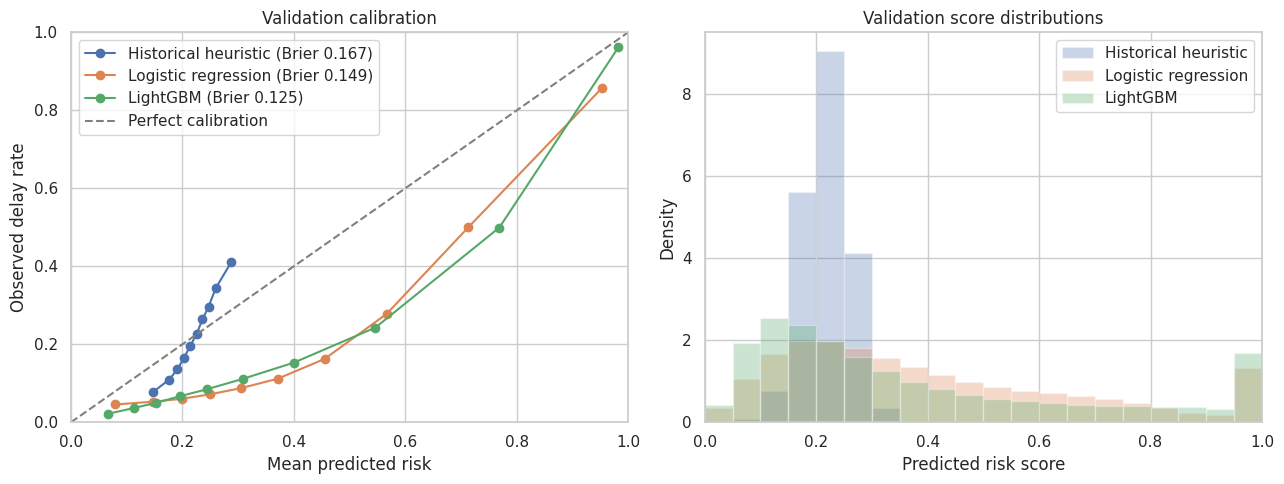


Saved: /kaggle/working/reports/validation_calibration_curves.png


In [14]:
# CELL 12 — Validation comparison and calibration curves

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

val_mask = model_df["split"].eq("val")
X_val = model_df.loc[val_mask, MODEL_FEATURES]
y_val = model_df.loc[val_mask, "is_delayed_15"].to_numpy(dtype="int8")

logistic_path = PROCESSED_DIR / "logistic_model.joblib"
lightgbm_path = PROCESSED_DIR / "lightgbm_model.txt"

if not logistic_path.exists():
    raise FileNotFoundError(f"Missing {logistic_path}. Run CELL 10.")
if not lightgbm_path.exists():
    raise FileNotFoundError(f"Missing {lightgbm_path}. Run CELL 11.")

logistic_model = joblib.load(logistic_path)
lightgbm_model = lgb.Booster(model_file=str(lightgbm_path))

scores = {
    "Historical heuristic": model_df.loc[
        val_mask, "baseline_risk_score"
    ].to_numpy(dtype="float32"),
    "Logistic regression": logistic_model.predict_proba(X_val)[:, 1].astype("float32"),
    "LightGBM": lightgbm_model.predict(
        X_val,
        num_iteration=lightgbm_model.best_iteration or -1,
    ).astype("float32"),
}

metric_files = {
    "Historical heuristic": REPORTS_DIR / "baseline_validation_metrics.json",
    "Logistic regression": REPORTS_DIR / "logistic_validation_metrics.json",
    "LightGBM": REPORTS_DIR / "lightgbm_validation_metrics.json",
}

rows = []
for name, path in metric_files.items():
    with open(path) as f:
        metrics = json.load(f)
    rows.append({
        "model": name,
        "ROC-AUC": metrics["roc_auc"],
        "PR-AUC": metrics["pr_auc_average_precision"],
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "F1": metrics["f1"],
        "Brier": metrics["brier_score"],
        "F1 threshold": metrics["threshold_selected_by_validation_f1"],
        "flagged %": metrics["share_flagged_pct"],
    })

comparison = pd.DataFrame(rows).set_index("model")
print("Validation model comparison:")
print(comparison.round(4).to_string())

fig, (ax_cal, ax_hist) = plt.subplots(1, 2, figsize=(13, 5))

for name, predicted in scores.items():
    observed_rate, mean_score = calibration_curve(
        y_val, predicted, n_bins=10, strategy="quantile"
    )
    brier = brier_score_loss(y_val, predicted)
    ax_cal.plot(mean_score, observed_rate, marker="o", label=f"{name} (Brier {brier:.3f})")
    ax_hist.hist(
        predicted,
        bins=np.linspace(0, 1, 21),
        density=True,
        alpha=0.3,
        label=name,
    )

ax_cal.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
ax_cal.set(
    title="Validation calibration",
    xlabel="Mean predicted risk",
    ylabel="Observed delay rate",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax_cal.legend()

ax_hist.set(
    title="Validation score distributions",
    xlabel="Predicted risk score",
    ylabel="Density",
    xlim=(0, 1),
)
ax_hist.legend()

fig.tight_layout()
calibration_path = REPORTS_DIR / "validation_calibration_curves.png"
fig.savefig(calibration_path, dpi=160, bbox_inches="tight")
plt.show()

print("\nSaved:", calibration_path)

In [15]:
# CELL 13 — Calibrate LightGBM and set validation thresholds

import json
import joblib
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss

calibration_mask = (
    model_df["split"].eq("val")
    & model_df["flight_date"].between("2007-07-01", "2007-09-30")
)
threshold_mask = (
    model_df["split"].eq("val")
    & model_df["flight_date"].between("2007-10-01", "2007-12-31")
)

if not calibration_mask.any() or not threshold_mask.any():
    raise ValueError("Calibration or threshold-selection period is empty.")

X_cal = model_df.loc[calibration_mask, MODEL_FEATURES]
y_cal = model_df.loc[calibration_mask, "is_delayed_15"].to_numpy(dtype="int8")
X_threshold = model_df.loc[threshold_mask, MODEL_FEATURES]
y_threshold = model_df.loc[threshold_mask, "is_delayed_15"].to_numpy(dtype="int8")

lightgbm_path = PROCESSED_DIR / "lightgbm_model.txt"
if not lightgbm_path.exists():
    raise FileNotFoundError(f"Missing {lightgbm_path}. Run CELL 11.")

lightgbm_model = lgb.Booster(model_file=str(lightgbm_path))
best_iteration = lightgbm_model.best_iteration or lightgbm_model.current_iteration()

raw_cal = lightgbm_model.predict(X_cal, num_iteration=best_iteration)
raw_threshold = lightgbm_model.predict(X_threshold, num_iteration=best_iteration)

calibrator = LogisticRegression(
    solver="lbfgs",
    C=1e6,
    max_iter=1000,
)
calibrator.fit(raw_cal.reshape(-1, 1), y_cal)

if calibrator.coef_[0, 0] <= 0:
    raise ValueError("Calibration mapping is not increasing; inspect model scores.")

calibrated_threshold = calibrator.predict_proba(
    raw_threshold.reshape(-1, 1)
)[:, 1]

watchlist_threshold = float(np.quantile(calibrated_threshold, 0.85))
proactive_threshold = float(np.quantile(calibrated_threshold, 0.95))

priority = np.select(
    [
        calibrated_threshold >= proactive_threshold,
        calibrated_threshold >= watchlist_threshold,
    ],
    [
        "Proactive intervention",
        "Watchlist",
    ],
    default="Normal monitoring",
)

priority_order = [
    "Normal monitoring",
    "Watchlist",
    "Proactive intervention",
]
summary = pd.DataFrame({
    "priority": pd.Categorical(priority, categories=priority_order, ordered=True),
    "is_delayed_15": y_threshold,
}).groupby("priority", observed=False).agg(
    flights=("is_delayed_15", "size"),
    delayed_flights=("is_delayed_15", "sum"),
)
summary["share_of_flights_pct"] = (
    summary["flights"] / len(y_threshold) * 100
).round(2)
summary["delay_rate_pct"] = (
    summary["delayed_flights"] / summary["flights"] * 100
).round(2)
summary["share_of_delays_captured_pct"] = (
    summary["delayed_flights"] / y_threshold.sum() * 100
).round(2)

print(f"Calibration rows (Jul-Sep 2007): {len(y_cal):,}")
print(f"Threshold rows (Oct-Dec 2007): {len(y_threshold):,}")
print(f"Sigmoid coefficient: {calibrator.coef_[0, 0]:.6f}")
print(f"Sigmoid intercept: {calibrator.intercept_[0]:.6f}")
print(f"Calibrated Brier score on threshold period: "
      f"{brier_score_loss(y_threshold, calibrated_threshold):.6f}")

print("\nPriority thresholds:")
print(f"Normal monitoring: calibrated risk < {watchlist_threshold:.4f}")
print(
    f"Watchlist: {watchlist_threshold:.4f} to "
    f"{proactive_threshold:.4f}"
)
print(f"Proactive intervention: calibrated risk >= {proactive_threshold:.4f}")

print("\nValidation workload and outcomes:")
print(summary.to_string())

calibrator_path = PROCESSED_DIR / "lightgbm_sigmoid_calibrator.joblib"
joblib.dump(calibrator, calibrator_path)

threshold_path = REPORTS_DIR / "operational_thresholds.json"
threshold_data = {
    "calibration_period": ["2007-07-01", "2007-09-30"],
    "threshold_selection_period": ["2007-10-01", "2007-12-31"],
    "watchlist_threshold": watchlist_threshold,
    "proactive_threshold": proactive_threshold,
    "policy": {
        "normal_monitoring": "Below the 85th validation percentile",
        "watchlist": "85th through 95th validation percentiles",
        "proactive_intervention": "Top 5% of validation risk scores",
    },
}
with open(threshold_path, "w") as f:
    json.dump(threshold_data, f, indent=2)

summary.to_csv(REPORTS_DIR / "validation_priority_tiers.csv")

print("\nSaved:", calibrator_path)
print("Saved:", threshold_path)
print("Saved:", REPORTS_DIR / "validation_priority_tiers.csv")

Calibration rows (Jul-Sep 2007): 1,330,620
Threshold rows (Oct-Dec 2007): 1,294,248
Sigmoid coefficient: 5.994425
Sigmoid intercept: -4.093929
Calibrated Brier score on threshold period: 0.093986

Priority thresholds:
Normal monitoring: calibrated risk < 0.6133
Watchlist: 0.6133 to 0.8691
Proactive intervention: calibrated risk >= 0.8691

Validation workload and outcomes:
                        flights  delayed_flights  share_of_flights_pct  delay_rate_pct  share_of_delays_captured_pct
priority                                                                                                            
Normal monitoring       1100110           120268                  85.0           10.93                         42.76
Watchlist                129425            96313                  10.0           74.42                         34.24
Proactive intervention    64713            64674                   5.0           99.94                         22.99

Saved: /kaggle/working/processed/lightg

Validation intervention-budget results:
                 ranking  budget_pct  selected_flights  delay_capture_pct  precision_pct  false_alarm_count  positive_delay_minutes_selected  missed_delayed_flights
      Random expectation         5.0            131244               5.00          22.27           102014.0                        1808053.0                555367.0
   Historical route rate         5.0            131244               7.70          34.32            86204.0                        3087316.0                539557.0
      Baseline heuristic         5.0            131244               9.64          42.93            74902.0                        3963715.0                528255.0
LightGBM calibrated risk         5.0            131244              22.44          99.94               83.0                       10940838.0                453436.0
      Random expectation        10.0            262487              10.00          22.27           204027.3                        3616

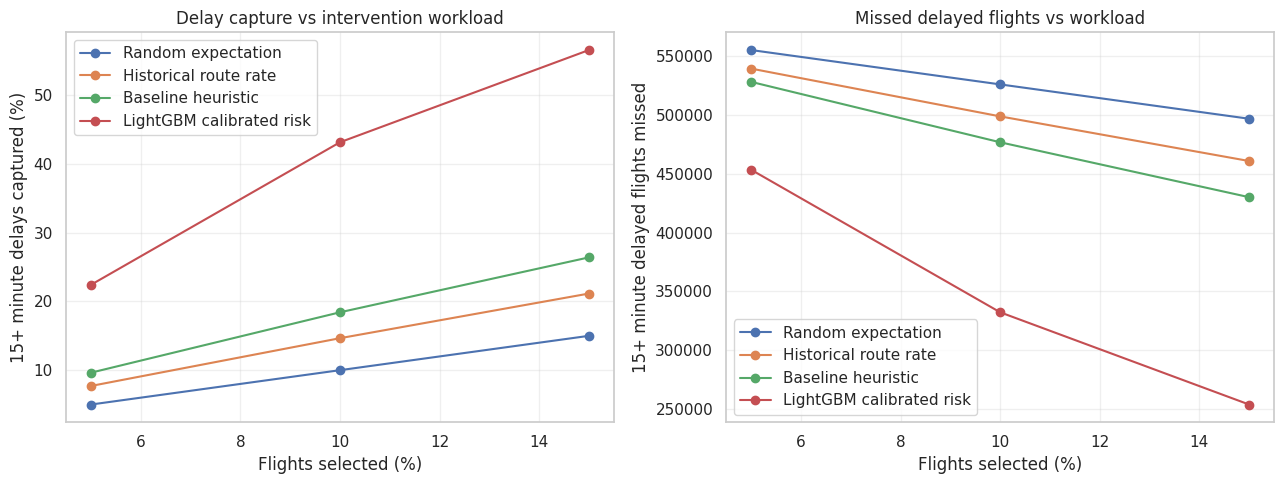


Saved: /kaggle/working/reports/validation_intervention_budget.csv
Saved: /kaggle/working/reports/validation_intervention_budget.png


In [16]:
# CELL 14 — Validation intervention-budget analysis

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

val_mask = model_df["split"].eq("val")

required = [
    "is_delayed_15", "dep_delay_minutes", "hist_route_delay_rate",
    "baseline_risk_score",
]
missing = [c for c in required if c not in model_df.columns]
if missing:
    raise KeyError(f"Missing intervention-analysis columns: {missing}")

y_val = model_df.loc[val_mask, "is_delayed_15"].to_numpy(dtype="int8")
delay_minutes = model_df.loc[val_mask, "dep_delay_minutes"].to_numpy(dtype="float32")
positive_delay_minutes = np.maximum(delay_minutes, 0)

route_score = model_df.loc[
    val_mask, "hist_route_delay_rate"
].to_numpy(dtype="float32")
baseline_score = model_df.loc[
    val_mask, "baseline_risk_score"
].to_numpy(dtype="float32")

X_val = model_df.loc[val_mask, MODEL_FEATURES]
lightgbm_model = lgb.Booster(
    model_file=str(PROCESSED_DIR / "lightgbm_model.txt")
)
calibrator = joblib.load(
    PROCESSED_DIR / "lightgbm_sigmoid_calibrator.joblib"
)
best_iteration = lightgbm_model.best_iteration or lightgbm_model.current_iteration()
raw_lightgbm_score = lightgbm_model.predict(
    X_val, num_iteration=best_iteration
)
lightgbm_score = calibrator.predict_proba(
    raw_lightgbm_score.reshape(-1, 1)
)[:, 1]

n = len(y_val)
total_delayed = int(y_val.sum())
total_positive_delay_minutes = float(positive_delay_minutes.sum())
budgets = [0.05, 0.10, 0.15]

rankings = {
    "Historical route rate": route_score,
    "Baseline heuristic": baseline_score,
    "LightGBM calibrated risk": lightgbm_score,
}

rows = []

for budget in budgets:
    selected_count = int(np.ceil(n * budget))
    expected_true_positives = selected_count * total_delayed / n

    rows.append({
        "ranking": "Random expectation",
        "budget_pct": budget * 100,
        "selected_flights": selected_count,
        "delay_capture_pct": budget * 100,
        "precision_pct": total_delayed / n * 100,
        "false_alarm_count": selected_count - expected_true_positives,
        "positive_delay_minutes_selected": (
            budget * total_positive_delay_minutes
        ),
        "missed_delayed_flights": total_delayed - expected_true_positives,
    })

    for name, score in rankings.items():
        selected_idx = np.argpartition(score, -selected_count)[-selected_count:]
        selected_y = y_val[selected_idx]
        true_positives = int(selected_y.sum())

        rows.append({
            "ranking": name,
            "budget_pct": budget * 100,
            "selected_flights": selected_count,
            "delay_capture_pct": true_positives / total_delayed * 100,
            "precision_pct": true_positives / selected_count * 100,
            "false_alarm_count": selected_count - true_positives,
            "positive_delay_minutes_selected": float(
                positive_delay_minutes[selected_idx].sum()
            ),
            "missed_delayed_flights": total_delayed - true_positives,
        })

results = pd.DataFrame(rows)

print("Validation intervention-budget results:")
print(
    results.round({
        "delay_capture_pct": 2,
        "precision_pct": 2,
        "false_alarm_count": 1,
        "positive_delay_minutes_selected": 0,
        "missed_delayed_flights": 1,
    }).to_string(index=False)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, group in results.groupby("ranking", sort=False):
    group = group.sort_values("budget_pct")
    axes[0].plot(
        group["budget_pct"],
        group["delay_capture_pct"],
        marker="o",
        label=name,
    )
    axes[1].plot(
        group["budget_pct"],
        group["missed_delayed_flights"],
        marker="o",
        label=name,
    )

axes[0].set(
    title="Delay capture vs intervention workload",
    xlabel="Flights selected (%)",
    ylabel="15+ minute delays captured (%)",
)
axes[1].set(
    title="Missed delayed flights vs workload",
    xlabel="Flights selected (%)",
    ylabel="15+ minute delayed flights missed",
)
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.tight_layout()
plot_path = REPORTS_DIR / "validation_intervention_budget.png"
fig.savefig(plot_path, dpi=160, bbox_inches="tight")
plt.show()

results_path = REPORTS_DIR / "validation_intervention_budget.csv"
results.to_csv(results_path, index=False)

print("\nSaved:", results_path)
print("Saved:", plot_path)


Historical heuristic confusion matrix (rows=actual, columns=predicted):
[[705544 571591]
 [122901 254275]]

Logistic regression confusion matrix (rows=actual, columns=predicted):
[[1132660  144475]
 [ 132615  244561]]

LightGBM calibrated confusion matrix (rows=actual, columns=predicted):
[[1184039   93096]
 [ 131901  245275]]

2008 test metrics:
                      ROC-AUC  PR-AUC  precision  recall      F1   Brier  validation_threshold  share_flagged_pct
model                                                                                                            
Historical heuristic   0.6551  0.3309     0.3079  0.6742  0.4227  0.1703                0.2208            49.9221
Logistic regression    0.8411  0.7078     0.6286  0.6484  0.6384  0.1554                0.6029            23.5165
LightGBM calibrated    0.8734  0.7828     0.7249  0.6503  0.6856  0.0997                0.4624            20.4539

LightGBM confusion matrix at the validation-selected proactive threshold:
[[127

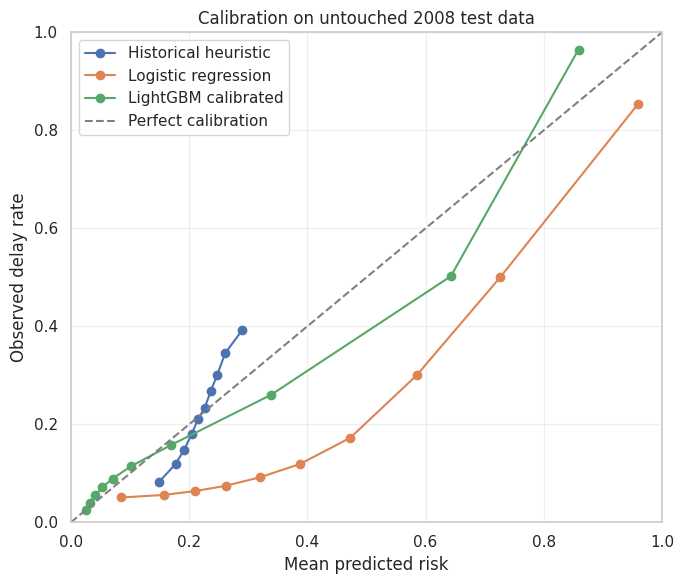


Saved: /kaggle/working/reports/test_model_metrics.json
Saved: /kaggle/working/reports/test_priority_tiers.csv
Saved: /kaggle/working/reports/test_calibration_curves.png


In [17]:
# CELL 15 — Final test evaluation

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)

test_mask = model_df["split"].eq("test")
val_mask = model_df["split"].eq("val")

if not test_mask.any() or not val_mask.any():
    raise ValueError("Validation or test split is empty.")

X_val = model_df.loc[val_mask, MODEL_FEATURES]
y_val = model_df.loc[val_mask, "is_delayed_15"].to_numpy(dtype="int8")
X_test = model_df.loc[test_mask, MODEL_FEATURES]
y_test = model_df.loc[test_mask, "is_delayed_15"].to_numpy(dtype="int8")

with open(REPORTS_DIR / "baseline_validation_metrics.json") as f:
    baseline_val_metrics = json.load(f)
with open(REPORTS_DIR / "logistic_validation_metrics.json") as f:
    logistic_val_metrics = json.load(f)
with open(REPORTS_DIR / "operational_thresholds.json") as f:
    operational_thresholds = json.load(f)

baseline_threshold = float(
    baseline_val_metrics["threshold_selected_by_validation_f1"]
)
logistic_threshold = float(
    logistic_val_metrics["threshold_selected_by_validation_f1"]
)
watchlist_threshold = float(operational_thresholds["watchlist_threshold"])
proactive_threshold = float(operational_thresholds["proactive_threshold"])

logistic_model = joblib.load(PROCESSED_DIR / "logistic_model.joblib")
lightgbm_model = lgb.Booster(
    model_file=str(PROCESSED_DIR / "lightgbm_model.txt")
)
calibrator = joblib.load(
    PROCESSED_DIR / "lightgbm_sigmoid_calibrator.joblib"
)
best_iteration = lightgbm_model.best_iteration or lightgbm_model.current_iteration()

val_raw_lgb = lightgbm_model.predict(X_val, num_iteration=best_iteration)
val_calibrated_lgb = calibrator.predict_proba(
    val_raw_lgb.reshape(-1, 1)
)[:, 1]

precision_curve, recall_curve, val_thresholds = precision_recall_curve(
    y_val, val_calibrated_lgb
)
f1_curve = (
    2 * precision_curve[:-1] * recall_curve[:-1]
    / (precision_curve[:-1] + recall_curve[:-1] + 1e-12)
)
lightgbm_f1_threshold = float(val_thresholds[int(np.argmax(f1_curve))])

test_scores = {
    "Historical heuristic": model_df.loc[
        test_mask, "baseline_risk_score"
    ].to_numpy(dtype="float32"),
    "Logistic regression": logistic_model.predict_proba(X_test)[:, 1].astype("float32"),
    "LightGBM calibrated": calibrator.predict_proba(
        lightgbm_model.predict(
            X_test, num_iteration=best_iteration
        ).reshape(-1, 1)
    )[:, 1].astype("float32"),
}
test_thresholds = {
    "Historical heuristic": baseline_threshold,
    "Logistic regression": logistic_threshold,
    "LightGBM calibrated": lightgbm_f1_threshold,
}

if not all(np.isfinite(scores).all() for scores in test_scores.values()):
    raise ValueError("One or more test score arrays contain non-finite values.")

test_metrics = []
for name, scores in test_scores.items():
    threshold = test_thresholds[name]
    predictions = (scores >= threshold).astype("int8")
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    test_metrics.append({
        "model": name,
        "ROC-AUC": roc_auc_score(y_test, scores),
        "PR-AUC": average_precision_score(y_test, scores),
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "Brier": brier_score_loss(y_test, scores),
        "validation_threshold": threshold,
        "share_flagged_pct": predictions.mean() * 100,
        "confusion_matrix_labels_0_1": cm.tolist(),
    })

    print(f"\n{name} confusion matrix (rows=actual, columns=predicted):")
    print(cm)

test_metrics_df = pd.DataFrame(test_metrics).set_index("model")
print("\n2008 test metrics:")
print(test_metrics_df.drop(columns="confusion_matrix_labels_0_1").round(4).to_string())

lightgbm_test_scores = test_scores["LightGBM calibrated"]
proactive_predictions = (lightgbm_test_scores >= proactive_threshold).astype("int8")
print("\nLightGBM confusion matrix at the validation-selected proactive threshold:")
print(confusion_matrix(y_test, proactive_predictions, labels=[0, 1]))
print(f"Proactive-threshold workload on test: {proactive_predictions.mean() * 100:.2f}%")

priority = np.select(
    [
        lightgbm_test_scores >= proactive_threshold,
        lightgbm_test_scores >= watchlist_threshold,
    ],
    ["Proactive intervention", "Watchlist"],
    default="Normal monitoring",
)
tier_summary = pd.DataFrame({
    "priority": priority,
    "is_delayed_15": y_test,
}).groupby("priority", sort=False).agg(
    flights=("is_delayed_15", "size"),
    delayed_flights=("is_delayed_15", "sum"),
)
tier_summary["share_of_flights_pct"] = (
    tier_summary["flights"] / len(y_test) * 100
).round(2)
tier_summary["delay_rate_pct"] = (
    tier_summary["delayed_flights"] / tier_summary["flights"] * 100
).round(2)
tier_summary["share_of_test_delays_captured_pct"] = (
    tier_summary["delayed_flights"] / y_test.sum() * 100
).round(2)

print("\nTest outcomes by frozen LightGBM priority tier:")
print(tier_summary.to_string())

fig, ax = plt.subplots(figsize=(7, 6))
for name, scores in test_scores.items():
    observed_rate, mean_score = calibration_curve(
        y_test, scores, n_bins=10, strategy="quantile"
    )
    ax.plot(mean_score, observed_rate, marker="o", label=name)

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
ax.set(
    title="Calibration on untouched 2008 test data",
    xlabel="Mean predicted risk",
    ylabel="Observed delay rate",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

calibration_path = REPORTS_DIR / "test_calibration_curves.png"
fig.savefig(calibration_path, dpi=160, bbox_inches="tight")
plt.show()

metrics_path = REPORTS_DIR / "test_model_metrics.json"
with open(metrics_path, "w") as f:
    json.dump(test_metrics, f, indent=2)

tier_path = REPORTS_DIR / "test_priority_tiers.csv"
tier_summary.to_csv(tier_path)

print("\nSaved:", metrics_path)
print("Saved:", tier_path)
print("Saved:", calibration_path)

In [18]:
# CELL 16 — 2006-to-2007 robustness check

import json
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

train06_mask = model_df["Year"].eq(2006)
test07_mask = model_df["Year"].eq(2007)

if not train06_mask.any() or not test07_mask.any():
    raise ValueError("2006 training or 2007 evaluation rows are missing.")

X_train06 = model_df.loc[train06_mask, MODEL_FEATURES].copy()
X_test07 = model_df.loc[test07_mask, MODEL_FEATURES].copy()
y_train06 = model_df.loc[train06_mask, "is_delayed_15"].to_numpy(dtype="int8")
y_test07 = model_df.loc[test07_mask, "is_delayed_15"].to_numpy(dtype="int8")

history06 = model_df.loc[train06_mask]

for feature_name, group_cols in GROUPS.items():
    rate_col = f"hist_{feature_name}_delay_rate"

    history = (
        history06.groupby(group_cols, observed=True, sort=False)
        .agg(
            prior_delays=("is_delayed_15", "sum"),
            prior_flights=("is_delayed_15", "size"),
        )
        .reset_index()
    )
    history[rate_col] = (
        history["prior_delays"] + MIN_HISTORY_COUNT * FALLBACK_RATE
    ) / (history["prior_flights"] + MIN_HISTORY_COUNT)

    matched = X_test07[group_cols].merge(
        history[[*group_cols, rate_col]],
        on=group_cols,
        how="left",
        validate="many_to_one",
        sort=False,
    )
    if len(matched) != len(X_test07):
        raise AssertionError(f"History join changed row count for {feature_name}.")
    X_test07[rate_col] = matched[rate_col].fillna(FALLBACK_RATE).to_numpy(
        dtype="float32"
    )

for col in CATEGORICAL_FEATURES:
    train_values = X_train06[col].astype("string").fillna("__MISSING__")
    test_values = X_test07[col].astype("string").fillna("__MISSING__")

    train_levels = train_values.drop_duplicates().tolist()
    if "__UNSEEN__" not in train_levels:
        train_levels.append("__UNSEEN__")

    test_values = test_values.where(
        test_values.isin(train_levels),
        "__UNSEEN__",
    )
    X_train06[col] = pd.Categorical(train_values, categories=train_levels)
    X_test07[col] = pd.Categorical(test_values, categories=train_levels)

with open(REPORTS_DIR / "lightgbm_validation_metrics.json") as f:
    selected_main_config = json.load(f)

selected_config = selected_main_config["selected_config"]
fixed_iterations = int(selected_main_config["best_iteration"])
scale_pos_weight_2006 = float(
    (y_train06 == 0).sum() / (y_train06 == 1).sum()
)

robust_params = {
    "objective": "binary",
    "metric": ["auc", "binary_logloss"],
    "boosting_type": "gbdt",
    "learning_rate": selected_config["learning_rate"],
    "num_leaves": selected_config["num_leaves"],
    "min_data_in_leaf": selected_config["min_data_in_leaf"],
    "feature_fraction": 0.9,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "scale_pos_weight": scale_pos_weight_2006,
    "max_bin": 63,
    "verbosity": -1,
    "num_threads": -1,
    "seed": RANDOM_SEED,
    "force_col_wise": True,
}

train06_set = lgb.Dataset(
    X_train06,
    label=y_train06,
    categorical_feature=CATEGORICAL_FEATURES,
    free_raw_data=True,
)

print(f"2006 training rows: {len(y_train06):,}")
print(f"2007 evaluation rows: {len(y_test07):,}")
print(f"Fixed boosting rounds: {fixed_iterations}")
print("Training on 2006 only...")

robust_model = lgb.train(
    robust_params,
    train06_set,
    num_boost_round=fixed_iterations,
    callbacks=[lgb.log_evaluation(100)],
)

score_test07 = robust_model.predict(X_test07)
robust_metrics = {
    "training_period": "2006-01-01 to 2006-12-31",
    "evaluation_period": "2007-01-01 to 2007-12-31",
    "training_rows": int(len(y_train06)),
    "evaluation_rows": int(len(y_test07)),
    "delay_rate_pct": float(y_test07.mean() * 100),
    "roc_auc": float(roc_auc_score(y_test07, score_test07)),
    "pr_auc_average_precision": float(
        average_precision_score(y_test07, score_test07)
    ),
    "raw_score_brier_diagnostic": float(
        brier_score_loss(y_test07, score_test07)
    ),
    "fixed_boosting_rounds": fixed_iterations,
    "scale_pos_weight": scale_pos_weight_2006,
}

print("\n2006-trained model, 2007 evaluation:")
for name, value in robust_metrics.items():
    if isinstance(value, float):
        print(f"{name}: {value:.6f}")
    else:
        print(f"{name}: {value}")

with open(REPORTS_DIR / "robustness_2006_train_2007_eval.json", "w") as f:
    json.dump(robust_metrics, f, indent=2)

robust_model_path = PROCESSED_DIR / "lightgbm_2006_train_model.txt"
robust_model.save_model(str(robust_model_path), num_iteration=fixed_iterations)

print("\nSaved:", REPORTS_DIR / "robustness_2006_train_2007_eval.json")
print("Saved:", robust_model_path)


2006 training rows: 5,095,376
2007 evaluation rows: 5,207,656
Fixed boosting rounds: 904
Training on 2006 only...

2006-trained model, 2007 evaluation:
training_period: 2006-01-01 to 2006-12-31
evaluation_period: 2007-01-01 to 2007-12-31
training_rows: 5095376
evaluation_rows: 5207656
delay_rate_pct: 22.756764
roc_auc: 0.872957
pr_auc_average_precision: 0.782021
raw_score_brier_diagnostic: 0.126238
fixed_boosting_rounds: 904
scale_pos_weight: 3.695152

Saved: /kaggle/working/reports/robustness_2006_train_2007_eval.json
Saved: /kaggle/working/processed/lightgbm_2006_train_model.txt


2008 test intervention-budget results:
                 ranking  budget_pct  selected_flights  delay_capture_pct  precision_pct  false_alarm_count  positive_delay_minutes_selected  missed_delayed_flights
      Random expectation         5.0             82716               5.00          22.80            63857.1                        1164706.0                358317.1
   Historical route rate         5.0             82716               7.37          33.59            54931.0                        1892078.0                349391.0
      Baseline heuristic         5.0             82716               8.54          38.96            50487.0                        2241566.0                344947.0
LightGBM calibrated risk         5.0             82716              21.92          99.94               46.0                        6846475.0                294506.0
      Random expectation        10.0            165432              10.00          22.80           127714.2                        23294

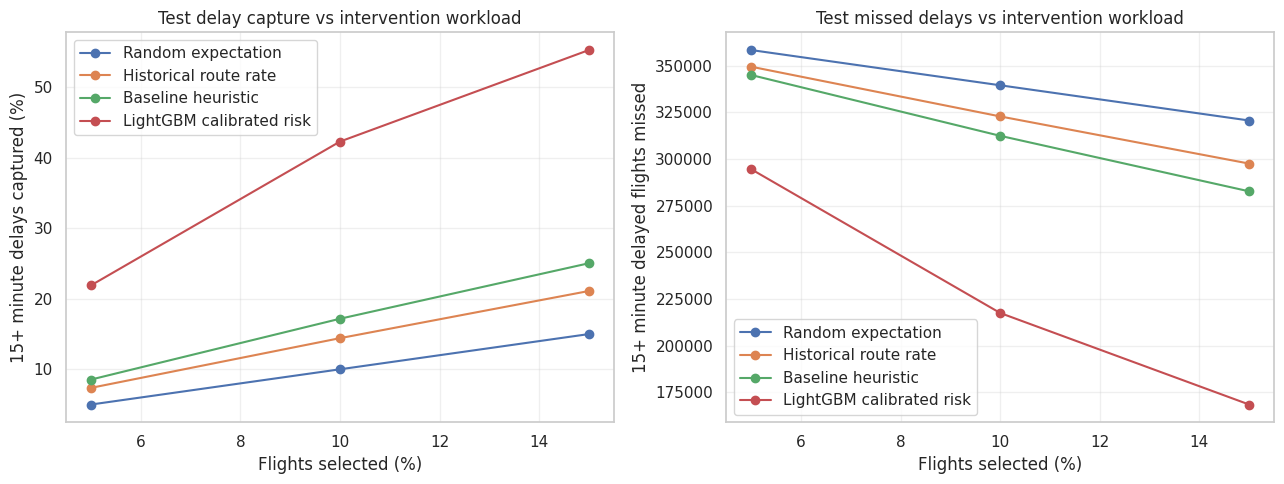


Saved: /kaggle/working/reports/test_intervention_budget.csv
Saved: /kaggle/working/reports/test_intervention_budget.png


In [19]:
# CELL 17 — Test intervention-budget analysis

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

test_mask = model_df["split"].eq("test")

required = [
    "is_delayed_15", "dep_delay_minutes", "hist_route_delay_rate",
    "baseline_risk_score",
]
missing = [c for c in required if c not in model_df.columns]
if missing:
    raise KeyError(f"Missing intervention-analysis columns: {missing}")

y_test = model_df.loc[test_mask, "is_delayed_15"].to_numpy(dtype="int8")
delay_minutes = model_df.loc[test_mask, "dep_delay_minutes"].to_numpy(dtype="float32")
positive_delay_minutes = np.maximum(delay_minutes, 0)

route_score = model_df.loc[
    test_mask, "hist_route_delay_rate"
].to_numpy(dtype="float32")
baseline_score = model_df.loc[
    test_mask, "baseline_risk_score"
].to_numpy(dtype="float32")

X_test = model_df.loc[test_mask, MODEL_FEATURES]
lightgbm_model = lgb.Booster(
    model_file=str(PROCESSED_DIR / "lightgbm_model.txt")
)
calibrator = joblib.load(
    PROCESSED_DIR / "lightgbm_sigmoid_calibrator.joblib"
)
best_iteration = lightgbm_model.best_iteration or lightgbm_model.current_iteration()

raw_score = lightgbm_model.predict(X_test, num_iteration=best_iteration)
lightgbm_score = calibrator.predict_proba(
    raw_score.reshape(-1, 1)
)[:, 1]

n = len(y_test)
total_delayed = int(y_test.sum())
total_positive_delay_minutes = float(positive_delay_minutes.sum())
budgets = [0.05, 0.10, 0.15]

rankings = {
    "Historical route rate": route_score,
    "Baseline heuristic": baseline_score,
    "LightGBM calibrated risk": lightgbm_score,
}
rows = []

for budget in budgets:
    selected_count = int(np.ceil(n * budget))
    expected_true_positives = selected_count * total_delayed / n

    rows.append({
        "ranking": "Random expectation",
        "budget_pct": budget * 100,
        "selected_flights": selected_count,
        "delay_capture_pct": budget * 100,
        "precision_pct": total_delayed / n * 100,
        "false_alarm_count": selected_count - expected_true_positives,
        "positive_delay_minutes_selected": (
            budget * total_positive_delay_minutes
        ),
        "missed_delayed_flights": total_delayed - expected_true_positives,
    })

    for name, score in rankings.items():
        selected_idx = np.argpartition(score, -selected_count)[-selected_count:]
        selected_y = y_test[selected_idx]
        true_positives = int(selected_y.sum())

        rows.append({
            "ranking": name,
            "budget_pct": budget * 100,
            "selected_flights": selected_count,
            "delay_capture_pct": true_positives / total_delayed * 100,
            "precision_pct": true_positives / selected_count * 100,
            "false_alarm_count": selected_count - true_positives,
            "positive_delay_minutes_selected": float(
                positive_delay_minutes[selected_idx].sum()
            ),
            "missed_delayed_flights": total_delayed - true_positives,
        })

results = pd.DataFrame(rows)

print("2008 test intervention-budget results:")
print(
    results.round({
        "delay_capture_pct": 2,
        "precision_pct": 2,
        "false_alarm_count": 1,
        "positive_delay_minutes_selected": 0,
        "missed_delayed_flights": 1,
    }).to_string(index=False)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, group in results.groupby("ranking", sort=False):
    group = group.sort_values("budget_pct")
    axes[0].plot(
        group["budget_pct"], group["delay_capture_pct"],
        marker="o", label=name,
    )
    axes[1].plot(
        group["budget_pct"], group["missed_delayed_flights"],
        marker="o", label=name,
    )

axes[0].set(
    title="Test delay capture vs intervention workload",
    xlabel="Flights selected (%)",
    ylabel="15+ minute delays captured (%)",
)
axes[1].set(
    title="Test missed delays vs intervention workload",
    xlabel="Flights selected (%)",
    ylabel="15+ minute delayed flights missed",
)
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.tight_layout()
plot_path = REPORTS_DIR / "test_intervention_budget.png"
fig.savefig(plot_path, dpi=160, bbox_inches="tight")
plt.show()

results_path = REPORTS_DIR / "test_intervention_budget.csv"
results.to_csv(results_path, index=False)

print("\nSaved:", results_path)
print("Saved:", plot_path)

In [21]:
import os
import joblib
import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

MODEL_PATH = "/kaggle/working/processed/lightgbm_model.txt"
CALIBRATOR_PATH = "/kaggle/working/processed/lightgbm_sigmoid_calibrator.joblib"
REPORT_PATH = "/kaggle/working/reports/test_subgroup_error_analysis.csv"

VALIDATION_F1_THRESHOLD = 0.4624
WATCHLIST_THRESHOLD = 0.6133
PROACTIVE_THRESHOLD = 0.8691

categorical_features = [
    "UniqueCarrier", "Origin", "Dest", "route",
    "Month", "DayOfMonth", "DayOfWeek", "sched_hour"
]

column_lookup = {column.lower(): column for column in model_df.columns}

target_col = next(
    (column_lookup[name] for name in [
        "is_delayed", "dep_del15", "dep_delay_15",
        "dep_delayed_15", "delayed", "target"
    ] if name in column_lookup),
    None
)

delay_col = next(
    (column_lookup[name] for name in [
        "dep_delay_minutes", "depdelayminutes",
        "dep_delay", "depdelay"
    ] if name in column_lookup),
    None
)

if delay_col is None:
    raise KeyError("Could not find departure delay minutes in model_df.")

booster = lgb.Booster(model_file=MODEL_PATH)
calibrator = joblib.load(CALIBRATOR_PATH)
feature_names = booster.feature_name()

required_groups = ["UniqueCarrier", "Origin", "sched_hour", "Month"]
missing = [column for column in required_groups + feature_names if column not in model_df.columns]
if missing:
    raise KeyError(f"Missing required columns: {missing}")

test_mask = model_df["split"].astype(str).eq("test")
test_rows = model_df.loc[test_mask, required_groups + [delay_col] + ([target_col] if target_col else [])].copy()
X_test = model_df.loc[test_mask, feature_names].copy()

categorical_names = {name.lower() for name in categorical_features}
categorical_model_features = [
    name for name in feature_names
    if name.lower() in categorical_names
]

for column in categorical_model_features:
    X_test[column] = X_test[column].astype("category")

print("Categorical model features:", categorical_model_features)

if target_col:
    test_rows["_actual"] = pd.to_numeric(test_rows[target_col], errors="coerce")
else:
    test_rows["_actual"] = (pd.to_numeric(test_rows[delay_col], errors="coerce") >= 15).astype(float)

valid = test_rows["_actual"].notna()
test_rows = test_rows.loc[valid].copy()
X_test = X_test.loc[test_rows.index]

test_rows["_actual"] = test_rows["_actual"].astype("int8")
raw_risk = booster.predict(X_test, num_iteration=904)
test_rows["_risk"] = calibrator.predict_proba(raw_risk.reshape(-1, 1))[:, 1]
test_rows["_predicted"] = (test_rows["_risk"] >= VALIDATION_F1_THRESHOLD).astype("int8")

test_rows["_delay_band"] = pd.cut(
    pd.to_numeric(test_rows[delay_col], errors="coerce"),
    bins=[-np.inf, 15, 30, 60, 120, np.inf],
    right=False,
    labels=["Under 15", "15–29", "30–59", "60–119", "120+"]
)

def summarize_group(slice_type, slice_value, group):
    actual = group["_actual"].to_numpy()
    predicted = group["_predicted"].to_numpy()
    risk = group["_risk"].to_numpy()

    tp = int(((actual == 1) & (predicted == 1)).sum())
    fp = int(((actual == 0) & (predicted == 1)).sum())
    fn = int(((actual == 1) & (predicted == 0)).sum())
    tn = int(((actual == 0) & (predicted == 0)).sum())

    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn) if tp + fn else np.nan
    f1 = 2 * precision * recall / (precision + recall) if pd.notna(precision) and pd.notna(recall) and precision + recall else 0

    both_classes = np.unique(actual).size == 2

    return {
        "slice_type": slice_type,
        "slice_value": str(slice_value),
        "flights": len(group),
        "delayed_flights": int(actual.sum()),
        "delay_rate_pct": 100 * actual.mean(),
        "predicted_positive": int(predicted.sum()),
        "precision_pct": 100 * precision if pd.notna(precision) else np.nan,
        "recall_pct": 100 * recall if pd.notna(recall) else np.nan,
        "f1_pct": 100 * f1,
        "false_alarms": fp,
        "false_alarm_rate_pct": 100 * fp / (fp + tn) if fp + tn else np.nan,
        "missed_delays": fn,
        "mean_calibrated_risk": risk.mean(),
        "proactive_share_pct": 100 * (risk >= PROACTIVE_THRESHOLD).mean(),
        "roc_auc": roc_auc_score(actual, risk) if both_classes else np.nan,
        "average_precision": average_precision_score(actual, risk) if both_classes else np.nan,
    }

results = []

for column in required_groups:
    for value, group in test_rows.groupby(column, observed=True, dropna=False):
        results.append(summarize_group(column, value, group))

for value, group in test_rows.groupby("_delay_band", observed=True, dropna=False):
    results.append(summarize_group("delay_band", value, group))

subgroup_results = pd.DataFrame(results)
os.makedirs(os.path.dirname(REPORT_PATH), exist_ok=True)
subgroup_results.to_csv(REPORT_PATH, index=False)

large_segments = subgroup_results[
    subgroup_results["slice_type"].ne("delay_band")
    & subgroup_results["flights"].ge(10_000)
]

print("Lowest-recall segments with at least 10,000 flights:")
print(
    large_segments.sort_values("recall_pct")
    .groupby("slice_type", group_keys=False)
    .head(5)[["slice_type", "slice_value", "flights", "delay_rate_pct",
              "precision_pct", "recall_pct", "false_alarms", "missed_delays"]]
    .round(2)
    .to_string(index=False)
)

print("\nResults by actual delay duration:")
print(
    subgroup_results[subgroup_results["slice_type"].eq("delay_band")]
    [["slice_value", "flights", "delay_rate_pct", "recall_pct",
      "proactive_share_pct", "missed_delays"]]
    .round(2)
    .to_string(index=False)
)

print(f"\nSaved: {REPORT_PATH}")

Categorical model features: ['UniqueCarrier', 'Origin', 'Dest', 'route', 'Month', 'DayofMonth', 'DayOfWeek', 'sched_hour']
Lowest-recall segments with at least 10,000 flights:
   slice_type slice_value  flights  delay_rate_pct  precision_pct  recall_pct  false_alarms  missed_delays
   sched_hour           6    87089            6.62          61.47        3.76           136           5551
UniqueCarrier          HA    10072            4.85          51.06        9.84            46            440
   sched_hour           7   100208            8.97          64.76       12.37           605           7875
       Origin         HNL    19376            7.28          71.36       19.77           112           1132
   sched_hour           8   120525           12.79          68.20       29.45          2117          10877
   sched_hour           9   115231           16.29          66.76       43.65          4078          10574
       Origin         MEM    26921           22.42          77.68       45.

In [22]:
import os
import lightgbm as lgb
import numpy as np
import pandas as pd

MODEL_PATH = "/kaggle/working/processed/lightgbm_model.txt"
REPORT_PATH = "/kaggle/working/reports/lightgbm_feature_importance_summary.csv"

booster = lgb.Booster(model_file=MODEL_PATH)

importance = pd.DataFrame({
    "feature": booster.feature_name(),
    "gain": booster.feature_importance(importance_type="gain"),
    "split_count": booster.feature_importance(importance_type="split"),
})

total_gain = importance["gain"].sum()
importance["gain_share_pct"] = (
    100 * importance["gain"] / total_gain if total_gain else 0
)
importance = importance.sort_values("gain", ascending=False).reset_index(drop=True)
importance["cumulative_gain_pct"] = importance["gain_share_pct"].cumsum()

def feature_family(feature):
    name = feature.lower()

    if name.startswith("hist_"):
        return "Historical delay rates"
    if name in {"uniquecarrier", "origin", "dest", "route"}:
        return "Carrier and route"
    if name in {"month", "dayofmonth", "dayofweek", "sched_hour"} or "sin" in name or "cos" in name:
        return "Schedule and calendar"
    if name in {"prior_leg_arrival_delay", "sched_turn_min"}:
        return "Aircraft rotation"
    if name in {"distance", "crseelapsedtime"}:
        return "Flight distance and duration"
    return "Other"

importance["feature_family"] = importance["feature"].map(feature_family)

family_summary = (
    importance.groupby("feature_family", as_index=False)
    .agg(gain=("gain", "sum"), features=("feature", "count"))
)
family_summary["gain_share_pct"] = 100 * family_summary["gain"] / total_gain
family_summary = family_summary.sort_values("gain_share_pct", ascending=False)

os.makedirs(os.path.dirname(REPORT_PATH), exist_ok=True)
importance.to_csv(REPORT_PATH, index=False)

print("Top features by gain:")
print(
    importance[["feature", "gain_share_pct", "cumulative_gain_pct", "split_count"]]
    .head(15)
    .round(2)
    .to_string(index=False)
)

print("\nGain share by feature family:")
print(family_summary[["feature_family", "features", "gain_share_pct"]].round(2).to_string(index=False))

print(f"\nSaved: {REPORT_PATH}")

Top features by gain:
                   feature  gain_share_pct  cumulative_gain_pct  split_count
   prior_leg_arrival_delay           44.41                44.41         2095
            sched_turn_min           15.33                59.74         1682
                     route           10.89                70.63        26895
            sched_time_sin           10.07                80.71          292
                sched_hour            4.31                85.02         3234
             UniqueCarrier            3.01                88.02         2129
                    Origin            2.69                90.72         1918
                      Dest            2.57                93.29         3947
                DayofMonth            2.21                95.50         8057
                     Month            1.44                96.94         3135
     hist_route_delay_rate            1.13                98.07          325
                 DayOfWeek            0.67            

In [23]:
import json, time, gc
import numpy as np
import pandas as pd
import lightgbm as lgb
import joblib
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, brier_score_loss, precision_recall_curve)

CUTOFF_MIN = 120   # predictions are made 2 hours before scheduled departure


model_df["has_prior_leg"] = model_df["prior_leg_arrival_delay"].notna()
model_df["prior_known_at_cutoff"] = (
    (model_df["sched_turn_min"] - model_df["prior_leg_arrival_delay"]) >= CUTOFF_MIN
)

print(model_df.groupby("split")[["has_prior_leg", "prior_known_at_cutoff"]].mean().round(3))

# Check 1: does the definition of sched_turn_min look right?
print(model_df.loc[model_df["has_prior_leg"], ["sched_turn_min", "prior_leg_arrival_delay"]].describe().round(1))

# Check 2: how delayed are flights whose aircraft lands AFTER the scheduled departure?
late_prior = (model_df["sched_turn_min"] - model_df["prior_leg_arrival_delay"]) < 0
test_m = model_df["split"].eq("test")
print("Test flights where the aircraft lands after scheduled departure:",
      f"{(late_prior & test_m).sum():,}",
      "| their delay rate:", round(model_df.loc[late_prior & test_m, "is_delayed_15"].mean(), 4))

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
       has_prior_leg  prior_known_at_cutoff
split                                      
train          0.714                  0.041
val            0.714                  0.043
test           0.705                  0.044
       sched_turn_min  prior_leg_arrival_delay
count       8526457.0                8526457.0
mean             58.7                      1.1
std              44.3                     20.3
min              20.0                   -298.0
25%              35.0                    -10.0
50%              47.0                     -3.0
75%              64.0                      8.0
max             360.0                    360.0
Test flights where the aircraft lands after scheduled departure: 0 | their delay rate: nan


In [24]:

with open(REPORTS_DIR / "lightgbm_validation_metrics.json") as f:
    lgb_meta = json.load(f)
cfg = lgb_meta["selected_config"]
if not isinstance(cfg, dict):                       # fallback if only the name was saved
    cfg = next(c for c in search_configs if c["name"] == cfg)
N_ROUNDS = int(lgb_meta["best_iteration"])
print("Config:", cfg, "| rounds:", N_ROUNDS)

masks = {s: model_df["split"].eq(s) for s in ["train", "val", "test"]}
cal_mask = masks["val"] & model_df["flight_date"].between("2007-07-01", "2007-09-30")
y = {k: model_df.loc[m, "is_delayed_15"].to_numpy(dtype="int8") for k, m in masks.items()}
y_cal = model_df.loc[cal_mask, "is_delayed_15"].to_numpy(dtype="int8")

SCENARIOS = ["A_current", "B_cutoff_aware", "C_no_prior_leg_delay"]

def make_X(mask, scenario):
    X = model_df.loc[mask, MODEL_FEATURES].copy()
    if scenario == "B_cutoff_aware":
        known = model_df.loc[mask, "prior_known_at_cutoff"].to_numpy()
        X["prior_leg_arrival_delay"] = X["prior_leg_arrival_delay"].where(known)  # NaN if not known yet
    elif scenario == "C_no_prior_leg_delay":
        X = X.drop(columns=["prior_leg_arrival_delay"])
    return X

def metrics_at(y_true, score, thr):
    pred = (score >= thr).astype("int8")
    return {
        "roc_auc": roc_auc_score(y_true, score),
        "pr_auc": average_precision_score(y_true, score),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "brier": brier_score_loss(y_true, score),
        "flagged_pct": pred.mean() * 100,
    }

def budget_rows(y_true, score, scenario, budgets=(0.05, 0.10, 0.15)):
    n, total, rows = len(y_true), int(y_true.sum()), []
    for b in budgets:
        k = int(np.ceil(n * b))
        idx = np.argpartition(score, -k)[-k:]
        tp = int(y_true[idx].sum())
        rows.append({"scenario": scenario, "budget_pct": b * 100,
                     "delay_capture_pct": tp / total * 100, "precision_pct": tp / k * 100})
    return rows

def run_scenario(name):
    t0 = time.time()
    if name == "A_current":
        booster = lgb.Booster(model_file=str(PROCESSED_DIR / "lightgbm_model.txt"))
        n_iter = booster.best_iteration or booster.current_iteration()
    else:
        X_tr = make_X(masks["train"], name)
        spw = float((y["train"] == 0).sum() / (y["train"] == 1).sum())
        params = {
            "objective": "binary", "metric": ["auc", "binary_logloss"], "boosting_type": "gbdt",
            "learning_rate": cfg["learning_rate"], "num_leaves": cfg["num_leaves"],
            "min_data_in_leaf": cfg["min_data_in_leaf"],
            "feature_fraction": 0.9, "bagging_fraction": 0.8, "bagging_freq": 1,
            "scale_pos_weight": spw, "max_bin": 63, "verbosity": -1, "num_threads": -1,
            "seed": RANDOM_SEED, "feature_fraction_seed": RANDOM_SEED,
            "bagging_seed": RANDOM_SEED, "force_col_wise": True,
        }
        dtrain = lgb.Dataset(X_tr, label=y["train"],
                             categorical_feature=CATEGORICAL_FEATURES, free_raw_data=True)
        booster = lgb.train(params, dtrain, num_boost_round=N_ROUNDS)   # fixed rounds, no tuning
        n_iter = N_ROUNDS
        booster.save_model(str(PROCESSED_DIR / f"lightgbm_{name}.txt"))
        del X_tr, dtrain; gc.collect()

    raw = lambda m: booster.predict(make_X(m, name), num_iteration=n_iter)

    # Calibrate on Jul-Sep 2007 (same protocol as the main notebook)
    cal = LogisticRegression(solver="lbfgs", C=1e6, max_iter=1000)
    cal.fit(raw(cal_mask).reshape(-1, 1), y_cal)
    to_prob = lambda r: cal.predict_proba(r.reshape(-1, 1))[:, 1]
    s_val, s_test = to_prob(raw(masks["val"])), to_prob(raw(masks["test"]))

    # F1 threshold chosen on validation only
    p, r, t = precision_recall_curve(y["val"], s_val)
    f1c = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    thr = float(t[int(np.argmax(f1c))])

    print(f"{name}: done in {(time.time() - t0) / 60:.1f} min | F1 threshold {thr:.4f}")
    return {"thr": thr, "s_val": s_val, "s_test": s_test,
            "val": metrics_at(y["val"], s_val, thr), "test": metrics_at(y["test"], s_test, thr)}

Config: {'name': '63_leaves', 'learning_rate': 0.04, 'num_leaves': 63, 'min_data_in_leaf': 2000} | rounds: 904


In [25]:
RESULTS = {}

In [26]:
RESULTS["A_current"] = run_scenario("A_current")

A_current: done in 5.9 min | F1 threshold 0.4624


In [27]:
RESULTS["B_cutoff_aware"] = run_scenario("B_cutoff_aware")

B_cutoff_aware: done in 12.6 min | F1 threshold 0.2435


In [28]:
RESULTS["C_no_prior_leg_delay"] = run_scenario("C_no_prior_leg_delay")

C_no_prior_leg_delay: done in 12.8 min | F1 threshold 0.2382


In [29]:
rows = []
for name, res in RESULTS.items():
    rows.append({"scenario": name, "split": "val",  **res["val"]})
    rows.append({"scenario": name, "split": "test", **res["test"]})
comparison = pd.DataFrame(rows).round(4)
comparison.to_csv(REPORTS_DIR / "scenario_comparison.csv", index=False)
print(comparison.to_string(index=False))

budget = pd.DataFrame([r for n, res in RESULTS.items()
                       for r in budget_rows(y["test"], res["s_test"], n)]).round(2)
budget.to_csv(REPORTS_DIR / "scenario_budget_test.csv", index=False)
print(budget.to_string(index=False))

            scenario split  roc_auc  pr_auc  precision  recall     f1  brier  flagged_pct
           A_current   val   0.8782  0.7867     0.7419  0.6473 0.6914 0.0957      19.4314
           A_current  test   0.8734  0.7828     0.7249  0.6503 0.6856 0.0997      20.4539
      B_cutoff_aware   val   0.7226  0.4338     0.3686  0.6338 0.4661 0.1534      38.2948
      B_cutoff_aware  test   0.7019  0.4073     0.3573  0.6126 0.4514 0.1600      39.0875
C_no_prior_leg_delay   val   0.7207  0.4321     0.3646  0.6393 0.4644 0.1537      39.0494
C_no_prior_leg_delay  test   0.7000  0.4067     0.3542  0.6160 0.4498 0.1602      39.6516
            scenario  budget_pct  delay_capture_pct  precision_pct
           A_current         5.0              21.92          99.94
           A_current        10.0              42.32          96.49
           A_current        15.0              55.31          84.08
      B_cutoff_aware         5.0              12.05          54.95
      B_cutoff_aware        10.0   

In [30]:
import shutil
shutil.make_archive("/kaggle/working/reports_export", "zip", str(REPORTS_DIR))

'/kaggle/working/reports_export.zip'